# Занятие 3. Скорости, матрица Якоби, обратная задача о скорости, кинематические характеристики — демонстрации

Ноутбук сопровождает Лекцию 3 (учебник Зенкевича и Ющенко, гл. 3, § 3.1–3.4 и 3.6). Все расчёты опираются на модуль курса `kinlib.py`; для сверки со стандартным пакетом используется Robotics Toolbox for Python (`roboticstoolbox`, версия 1.1.1). Сквозной пример — коллаборативный робот UR5e с официальной таблицей ДХ производителя (`make_ur5e()`), плоские двух- и трёхзвенники служат «микроскопом», PUMA 560 — пример учебника (`make_puma('book')` — расстановка осей лекций, `make_puma('rtb')` — таблица Robotics Toolbox).

**Соглашение о порядке блоков.** В лекции скорость тела записывается как $\boldsymbol{\mathcal V}=(\boldsymbol\omega;\mathbf v)$, и геометрическая матрица Якоби $J$ имеет строки в том же порядке. Свойство `RobotSerial.jacobian` и функции Robotics Toolbox возвращают порядок $[\mathbf v;\boldsymbol\omega]$; порядок лекции дают метод `jacobian_book()` и помощник `vw_to_wv()` из первой ячейки кода. Коэффициент демпфирования обозначается $\mu$, пределы скоростей и ускорений сочленений — $C_i=\dot q_i^{\max}$ и $b_i=\ddot q_i^{\max}$ (краткие имена учебника).

**Как пользоваться.** Демонстрации пронумерованы в порядке показа на занятии и в порядке таблицы «Связь с демонстрациями» конспекта. Каждая заканчивается сверкой с числами конспекта: строка «совпадает» означает, что расчёт отличается от числа в тексте не больше чем на половину последнего знака, строка «РАСХОДИТСЯ» — что текст и расчёт нужно согласовать. Сводка сверки — в последней ячейке. В большинстве ячеек есть переключатель `BREAK = False`: поставьте `True` и выполните ячейку заново — это режим «сломай и посмотри», в котором показана типичная ошибка (что именно ломается, сказано перед ячейкой). Интерактивная модель в демонстрации 13 работает только при живом запуске.

| № | Демонстрация | Раздел конспекта | Что получится |
|---|---|---|---|
| 1 | $\dot R=\Lambda(\boldsymbol\omega)R$ численно | § 3.1 | $\dot RR^{\mathrm T}$ кососимметрична, из неё читается $\boldsymbol\omega$; $\mathbf v_M=\mathbf v_0+\boldsymbol\omega\times\tilde{\mathbf r}$ |
| 2 | Прямая задача о скорости двухзвенника | § 3.3, пример 3.1 | $\boldsymbol{\mathcal V}=\mathbf j_1\dot q_1+\mathbf j_2\dot q_2$ совпадает с дифференцированием ПЗК |
| 3 | Якобиан UR5e по столбцам и сверка с Robotics Toolbox | § 3.3 | `jacob0` = `kinlib.jacobian` до $2\cdot10^{-16}$; `jacobe` = $\operatorname{diag}(R^{\mathrm T},R^{\mathrm T})$·`jacob0`; вылет TCP 0,1 м: $\sigma_{\max}$ 2,019 → 2,055 |
| 4 | Геометрический и аналитический якобианы UR5e | § 3.3 | углы ZYZ $(-1{,}893;\ 1{,}030;\ 1{,}349)$; угловые строки различаются до 1,54, после $\operatorname{diag}(W,E)$ — до $4\cdot10^{-7}$ |
| 5 | Ошибка ориентации при конечном повороте | § 3.4 | таблица 30/90/150/179°; контур $K=1$ от 179° до 1°: 9,5 с против 5,2 с |
| 6 | Двухзвенник у границы зоны | § 3.5, примеры 3.2, 3.4 | $\lVert\dot{\mathbf q}\rVert$ = 0,129/0,358/1,12/3,54 рад/с; DLS: 0,852 и 0,497 рад/с, 0,076 и 0,044 м/с |
| 7 | Особые конфигурации шестизвенников | § 3.6–3.7, примеры 3.3, 3.3а | PUMA: $D_{123}=a_2y_{34}x_{14}$, $D_{456}=-s_5$; UR5e: формула $\det J$, кистевая особенность, разрыв $J^{+}$ (0,35 рад/с при невязке 22,5 % против 6,39 рад/с) |
| 8 | Избыточный плоский трёхзвенник | § 3.7, пример 3.4а | $P\boldsymbol\xi=(-0{,}151;\ 0{,}317;\ -0{,}253)$, $\dot g=0{,}187$; за 5 с — $(7{,}4^\circ;\ 69{,}0^\circ;\ 45{,}9^\circ)$, дрейф $2\cdot10^{-8}$ м |
| 9 | Сфера, эллипс, взвешенный эллипс и многоугольник | § 3.8, примеры 3.5, 3.6 | вершины 0,61 и 0,41 м/с, вдоль $y$ 0,1 м/с; вдоль оси эллипса 0,19 против 0,83; взвешенный эллипс 0,51/0,098, ось −2,3° |
| 10 | Меры качества конфигурации | § 3.4, § 3.8 | 2R: max $w$ при 90°, min $\kappa(J)=1{,}618$ при 131,8°; UR5e: $\kappa(J)$ = 10,9 в м и 1872 в мм |
| 11 | Мобильность и манипулятивность | § 3.9 | $\mathcal M=0{,}2\lvert\sin q_2\rvert$; мобильность по направлению 0,1 и 0,5 м/с; карта UR5e в плоскости $(q_2,q_3)$ |
| 12 | Двойственность скоростей и сил | § 3.10 | полуоси 1,618/0,618 и 0,618/1,618 вдоль общих осей; сила вдоль вытянутой руки даёт $\boldsymbol\tau=0$ |
| 13 | Приемистость и интерактивная модель | § 3.11 | многоугольники допустимых ускорений из покоя; ползунки: эллипсы скоростей и сил, многоугольник |
| 14 | Ведём инструмент UR5e по прямой | § 3.12 | разомкнутый и замкнутый контур; насыщение: 0,065 м/с вдоль $x_0$ против 0,128 м/с под 95° и 0,86 рад/с |

In [1]:
import sys, os, time, warnings
sys.path.insert(0, os.path.abspath('.'))          # kinlib.py лежит рядом с ноутбуком
warnings.filterwarnings('ignore')                 # предупреждения pkg_resources и т. п.
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation
from kinlib import *
np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.dpi'] = 100
%matplotlib inline

E3, Z3 = np.eye(3), np.zeros((3, 3))
def blk(A, B):
    """Блочно-диагональная матрица diag(A, B)."""
    return np.block([[A, np.zeros((A.shape[0], B.shape[1]))], [np.zeros((B.shape[0], A.shape[1])), B]])

def vw_to_wv(J):
    """[v; ω] (kinlib.jacobian, Robotics Toolbox, Сицилиано) -> (ω; v) (порядок лекции)."""
    J = np.asarray(J)
    return np.vstack([J[3:6], J[0:3]])

def svals(J):
    return np.linalg.svd(J, compute_uv=False)

# ---- сверка с конспектом: число из Лекции_03.md записывается строкой, как в тексте ('0,129')
CHECKS = []
def check(name, value, lecture, unit='', src='конспект'):
    """Совпадает, если расчёт отличается от числа конспекта не больше чем на половину его последнего знака.
    src — откуда взято число: 'конспект' (Лекция_03.md) или 'план демонстраций' (числа, которых в тексте лекции пока нет)."""
    s = lecture.replace('−', '-')
    ref = float(s.replace(',', '.'))
    dec = len(s.split(',')[1]) if ',' in s else 0
    ok = abs(value - ref) <= 0.5 * 10 ** (-dec) * 1.0001
    CHECKS.append((name, ok))
    print('  %s  %s: расчёт %.*f, %s %s %s' % ('совпадает ' if ok else 'РАСХОДИТСЯ', name, dec + 1, value, src, lecture, unit))
    return ok

def check_small(name, value, lecture):
    """Для оценок вида «до 2·10⁻¹⁶»: lecture = '2e-16'; совпадает, если |расчёт| < (2 + 0,5)·10⁻¹⁶."""
    m, e = lecture.split('e')
    ok = abs(value) < (float(m) + 0.5) * 10 ** int(e)
    CHECKS.append((name, ok))
    print('  %s  %s: расчёт %.1e, конспект «до %s»' % ('совпадает ' if ok else 'РАСХОДИТСЯ', name, value, lecture))
    return ok

# «Конфигурация раздела 3.3» — рабочая поза UR5e, к которой конспект возвращается много раз
Q33 = np.array([0.3, -1.2, 1.4, -1.0, 0.8, 0.4])

## Демонстрация 1. Вращение твёрдого тела: $\dot R=\Lambda(\boldsymbol\omega)R$ численно (§ 3.1)

Возьмём вращение с постоянной угловой скоростью $\boldsymbol\omega$ из начальной ориентации $R_0$, $R(t)=\exp\big(\Lambda(\boldsymbol\omega)t\big)R_0$, найдём производную матрицы поворота центральными разностями и убедимся, что произведение $\dot RR^{\mathrm T}$ — кососимметрическая матрица, три независимых элемента которой и есть компоненты $\boldsymbol\omega$ (формулы (3.5) и (3.11)). Попутно проверим четвёртое свойство $\Lambda(R\mathbf a)=R\Lambda(\mathbf a)R^{\mathrm T}$ и распределение скоростей (3.7): $\mathbf v_M=\mathbf v_0+\boldsymbol\omega\times\tilde{\mathbf r}$, где $\tilde{\mathbf r}=R\mathbf r'$ — вектор от полюса к точке в осях неподвижной системы.

**Сломай и посмотри** (`BREAK = True`): вместо $\dot RR^{\mathrm T}$ берётся $R^{\mathrm T}\dot R$. Эта матрица тоже кососимметрична, но из неё читается угловая скорость в осях тела $R^{\mathrm T}\boldsymbol\omega$, а не $\boldsymbol\omega$ — частая путаница при чтении чужого кода.

In [2]:
BREAK = False
w = np.array([0.3, -0.5, 1.0])                         # угловая скорость, рад/с
R0 = Rotation.from_euler('xyz', [0.4, -0.7, 1.1]).as_matrix()       # начальная ориентация тела
R = lambda t: Rotation.from_rotvec(w * t).as_matrix() @ R0          # вращение с постоянной ω вокруг неподвижной оси
t0, h = 0.7, 1e-6
Rdot = (R(t0 + h) - R(t0 - h)) / (2 * h)               # центральная разность
L = R(t0).T @ Rdot if BREAK else Rdot @ R(t0).T
print('Λ = Ṙ Rᵀ =' if not BREAK else 'СЛОМАНО: Rᵀ Ṙ =', '\n', L.round(4))
print('max|Λ + Λᵀ| = %.1e  — матрица кососимметрична' % np.abs(L + L.T).max())
print('vee(Λ) =', vee(L).round(4), '   заданная ω =', w, '   Rᵀω =', (R(t0).T @ w).round(4))

a = np.array([0.2, 0.7, -0.4]); Rr = R(t0)
print('свойство 4: max|Λ(Ra) − RΛ(a)Rᵀ| = %.1e' % np.abs(skew(Rr @ a) - Rr @ skew(a) @ Rr.T).max())

# распределение скоростей: точка тела r(t) = p(t) + R(t) r', полюс движется с v_0
rp = np.array([0.5, 0.2, -0.3]); v0 = np.array([0.1, 0.0, 0.0])
r = lambda t: v0 * t + R(t) @ rp
v_num = (r(t0 + h) - r(t0 - h)) / (2 * h)
v_formula = v0 + np.cross(w, R(t0) @ rp)
print('v_M численно      =', v_num.round(4))
print('v_0 + ω × r̃ (3.7) =', v_formula.round(4), '   расхождение %.1e' % np.abs(v_num - v_formula).max())

Λ = Ṙ Rᵀ = 
 [[-0.  -1.  -0.5]
 [ 1.  -0.  -0.3]
 [ 0.5  0.3  0. ]]
max|Λ + Λᵀ| = 6.3e-11  — матрица кососимметрична
vee(Λ) = [ 0.3 -0.5  1. ]    заданная ω = [ 0.3 -0.5  1. ]    Rᵀω = [ 0.4075 -0.0797  1.0806]
свойство 4: max|Λ(Ra) − RΛ(a)Rᵀ| = 2.2e-16
v_M численно      = [-0.361  -0.5138 -0.1186]
v_0 + ω × r̃ (3.7) = [-0.361  -0.5138 -0.1186]    расхождение 6.9e-11


## Демонстрация 2. Прямая задача о скорости двухзвенника (§ 3.3, пример 3.1)

Плоский двухзвенник с равными звеньями $a=1$ м построим как цепь ДХ средствами `kinlib` и получим полную матрицу $6\times2$ по столбцам (3.62). Первые две строки нулевые, третья состоит из единиц ($\omega_z=\dot q_1+\dot q_2$), четвёртая и пятая образуют блок $J_v$ примера 3.1. Скорость схвата — сумма вкладов столбцов $\mathbf j_k\dot q_k$: каждый вклад касателен к дуге, которую описал бы схват, если бы двигалось только $k$-е сочленение. Сравним результат с конечной разностью прямой задачи о положении.

**Сломай и посмотри** (`BREAK = True`): второй столбец считается по вектору $\mathbf p_{1,2}$, взятому от основания, а не от оси второго сочленения, то есть $\mathbf z_1\times\mathbf p_2$ вместо $\mathbf z_1\times(\mathbf p_2-\mathbf p_1)$. Вклад второго сочленения перестаёт быть касательным к его дуге, и сверка с ПЗК расходится.

J двухзвенника по столбцам (3.62), порядок (ω; v):
 [[ 0.     0.   ]
 [ 0.     0.   ]
 [ 1.     1.   ]
 [-1.5   -1.   ]
 [ 0.866  0.   ]
 [ 0.     0.   ]]
блок J_v совпадает с формулой примера 3.1: True
j1 = z0 × p02 = [-1.5    0.866]    j2 = z1 × p12 = [-1.  0.] 
v = j1 q̇1 + j2 q̇2 = [0.05  0.433]    конечная разность ПЗК: [0.05  0.433]    расхождение 8.6e-11
ω_z = q̇1 + q̇2 = -0.3 рад/с


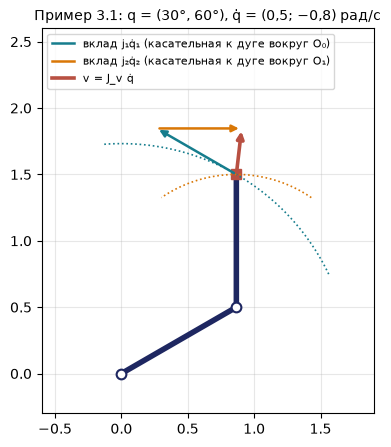

In [3]:
BREAK = False
a = 1.0; l = (a, a)
q = np.radians([30., 60.]); qd = np.array([0.5, -0.8])
two = RobotSerial(np.array([[0., a, 0., 0.], [0., a, 0., 0.]]))   # строки | d | a | α | θ0 |
two.forward(q); J6 = two.jacobian_book()                           # строки (ω_x, ω_y, ω_z, v_x, v_y, v_z)
print('J двухзвенника по столбцам (3.62), порядок (ω; v):\n', J6.round(4))
Jv = jac2r(q, l)
print('блок J_v совпадает с формулой примера 3.1:', np.allclose(J6[3:5], Jv))
p1 = np.array([a * np.cos(q[0]), a * np.sin(q[0])]); p2, _ = fk2r(q, l)
z = np.array([0, 0, 1.])
j1 = np.cross(z, np.r_[p2, 0])[:2]
j2 = np.cross(z, np.r_[p2 if BREAK else p2 - p1, 0])[:2]
v = j1 * qd[0] + j2 * qd[1]
pA, _ = fk2r(q - 1e-6 * qd, l); pB, _ = fk2r(q + 1e-6 * qd, l)
v_fd = (pB - pA) / 2e-6
print('j1 = z0 × p02 =', j1.round(4), '   j2 = z1 × p12 =', j2.round(4), '(СЛОМАНО)' if BREAK else '')
print('v = j1 q̇1 + j2 q̇2 =', v.round(4), '   конечная разность ПЗК:', v_fd.round(4), '   расхождение %.1e' % np.abs(v - v_fd).max())
print('ω_z = q̇1 + q̇2 =', round(float(J6[2] @ qd), 4), 'рад/с')

fig, ax = plt.subplots(figsize=(6.2, 5))
pts = draw_arm2d(ax, q, l)
tt = np.linspace(-0.6, 0.6, 50)
for ctr, rad, col in ((np.zeros(2), np.linalg.norm(p2), TEAL), (p1, np.linalg.norm(p2 - p1), AMB)):
    ang = np.arctan2(*(p2 - ctr)[::-1]) + tt
    ax.plot(ctr[0] + rad * np.cos(ang), ctr[1] + rad * np.sin(ang), ls=':', color=col, lw=1.2)
k = 0.8                                                             # масштаб стрелок
ax.annotate('', p2 + k * j1 * qd[0], p2, arrowprops=dict(arrowstyle='-|>', color=TEAL, lw=1.8))
ax.annotate('', p2 + k * (j1 * qd[0] + j2 * qd[1]), p2 + k * j1 * qd[0], arrowprops=dict(arrowstyle='-|>', color=AMB, lw=1.8))
ax.annotate('', p2 + k * v, p2, arrowprops=dict(arrowstyle='-|>', color=RED, lw=2.6))
for col, lab, lw in ((TEAL, 'вклад j₁q̇₁ (касательная к дуге вокруг O₀)', 1.8), (AMB, 'вклад j₂q̇₂ (касательная к дуге вокруг O₁)', 1.8), (RED, 'v = J_v q̇', 2.6)):
    ax.plot([], [], color=col, lw=lw, label=lab)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8, loc='upper left'); ax.set_xlim(-0.6, 1.9); ax.set_ylim(-0.3, 2.6)
ax.set_title('Пример 3.1: q = (30°, 60°), q̇ = (0,5; −0,8) рад/с', fontsize=10); plt.show()

## Демонстрация 3. Якобиан UR5e по столбцам и сверка с Robotics Toolbox (§ 3.3)

Берём UR5e в «конфигурации раздела 3.3» $\mathbf q=(0{,}3;\ -1{,}2;\ 1{,}4;\ -1{,}0;\ 0{,}8;\ 0{,}4)$ рад и проверяем по таблице соглашений конспекта:

1. столбцы (3.62) совпадают с конечными разностями прямой задачи;
2. Robotics Toolbox, построенный по той же таблице ДХ (`DHRobot` из `UR5E_DH`), даёт `jacob0`, совпадающий с `kinlib.jacobian` (порядок $[\mathbf v;\boldsymbol\omega]$), а `jacobe` — это та же матрица в осях схвата, $\operatorname{diag}(R_N^{\mathrm T},R_N^{\mathrm T})$·`jacob0`;
3. после перестановки блоков к порядку курса обе библиотеки дают одну матрицу $J$; пространственный якобиан Линча и Парка $J_s$, собранный из винтовых осей $(\mathbf z_{k-1};\ -\mathbf z_{k-1}\times\mathbf p_{k-1})$, связан с ней формулой $J=\begin{pmatrix}E&0\\-\Lambda(\mathbf p_N)&E\end{pmatrix}J_s$;
4. перенос точки приведения: при вылете инструмента $\mathbf r$ $J_{\mathrm{TCP}}=\begin{pmatrix}E&0\\-\Lambda(\mathbf r)&E\end{pmatrix}J$; ранг не меняется, сингулярные числа меняются.

**Сломай и посмотри** (`BREAK = True`): матрицы из Robotics Toolbox сравниваются с `jacobian_book()` без перестановки блоков, а смена TCP выполняется со знаком «плюс» перед $\Lambda(\mathbf r)$. Обе ошибки дают расхождения порядка единицы — именно так они и выглядят в домашних заданиях.

J UR5e в порядке курса (ω; v):
 [[ 0.      0.2955  0.2955  0.2955 -0.6853 -0.2716]
 [ 0.     -0.9553 -0.9553 -0.9553 -0.212  -0.8133]
 [ 1.      0.      0.      0.     -0.6967  0.5146]
 [ 0.3886 -0.2866  0.0918  0.0174 -0.0673 -0.    ]
 [-0.5703 -0.0887  0.0284  0.0054  0.054   0.    ]
 [ 0.     -0.6597 -0.5057 -0.1213  0.0498 -0.    ]]
1) max|J − конечные разности ПЗК| = 3.1e-07
2) max|rtb.jacob0 − kinlib.jacobian| = 2.2e-16 (оба [v; ω])
   max|rtb.jacobe − diag(Rᵀ,Rᵀ)·jacob0| = 1.9e-16
3) max|vw_to_wv(jacob0) − J| = 2.2e-16
   J = [[E,0],[−Λ(p_N),E]]·J_s: 1.1e-16
   J = diag(R_N,R_N)·J_b, J_b = vw_to_wv(jacobe): 2.2e-16
   мера Йошикавы: rtb.manipulability = 0.07187, √det(JJᵀ) = 0.07187
4) смена TCP: max|J_TCP,v − конечные разности| = 7.5e-11
   ранг J = 6, ранг J_TCP = 6
   σ(J)     = [2.019 1.456 0.864 0.446 0.342 0.186]
   σ(J_TCP) = [2.055 1.504 0.879 0.431 0.329 0.187]
Сверка с конспектом:
  совпадает   jacob0 и kinlib.jacobian: расчёт 2.2e-16, конспект «до 2e-16»
  совпадает   

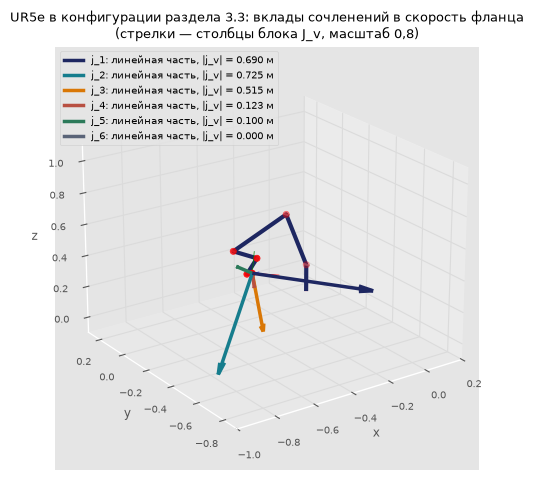

In [4]:
BREAK = False
import roboticstoolbox as rtb
ur = make_ur5e(); q = Q33.copy()
T = ur.forward(q.copy()); pN = T.t_3_1.ravel().copy(); RN = T.r_3_3.copy()
J = ur.jacobian_book()                                  # (ω; v), столбцы (3.62)
print('J UR5e в порядке курса (ω; v):\n', J.round(4))
print('1) max|J − конечные разности ПЗК| = %.1e' % np.abs(J - vw_to_wv(jacobian_numeric(ur, q))).max())

rob = rtb.DHRobot([rtb.RevoluteDH(d=d, a=a_, alpha=al, offset=th) for d, a_, al, th in UR5E_DH], name='UR5e')
J0, Je = rob.jacob0(q), rob.jacobe(q)
d0 = np.abs(J0 - ur.jacobian).max()
print('2) max|rtb.jacob0 − kinlib.jacobian| = %.1e (оба [v; ω])' % d0)
print('   max|rtb.jacobe − diag(Rᵀ,Rᵀ)·jacob0| = %.1e' % np.abs(Je - blk(RN.T, RN.T) @ J0).max())
if BREAK:
    print('   СЛОМАНО: без перестановки блоков max|jacob0 − jacobian_book| = %.3f' % np.abs(J0 - J).max())
print('3) max|vw_to_wv(jacob0) − J| = %.1e' % np.abs(vw_to_wv(J0) - J).max())
fr = [np.eye(4)] + [f.t_4_4 for f in ur.axis_frames]
Js = np.column_stack([np.r_[F[:3, 2], -np.cross(F[:3, 2], F[:3, 3])] for F in fr[:6]])   # винтовые оси S_k
print('   J = [[E,0],[−Λ(p_N),E]]·J_s: %.1e' % np.abs(np.block([[E3, Z3], [-skew(pN), E3]]) @ Js - J).max())
print('   J = diag(R_N,R_N)·J_b, J_b = vw_to_wv(jacobe): %.1e' % np.abs(blk(RN, RN) @ vw_to_wv(Je) - J).max())
print('   мера Йошикавы: rtb.manipulability = %.5f, √det(JJᵀ) = %.5f' % (rob.manipulability(q), np.sqrt(np.linalg.det(J @ J.T))))

r = RN @ np.array([0., 0., 0.1])                           # вылет 0,1 м вдоль оси z фланца, в осях базы
Jtcp = np.block([[E3, Z3], [(skew(r) if BREAK else -skew(r)), E3]]) @ J
def p_tcp(qq):
    TT = ur.forward(qq.copy()); return TT.t_3_1.ravel() + TT.r_3_3 @ np.array([0., 0., 0.1])
Jn = np.column_stack([(p_tcp(q + 1e-6 * e) - p_tcp(q - 1e-6 * e)) / 2e-6 for e in np.eye(6)]); ur.forward(q.copy())
print('4) смена TCP: max|J_TCP,v − конечные разности| = %.1e%s' % (np.abs(Jtcp[3:] - Jn).max(), '  (СЛОМАНО: знак +Λ(r))' if BREAK else ''))
print('   ранг J = %d, ранг J_TCP = %d' % (np.linalg.matrix_rank(J), np.linalg.matrix_rank(Jtcp)))
print('   σ(J)     =', svals(J).round(3)); print('   σ(J_TCP) =', svals(Jtcp).round(3))
print('Сверка с конспектом:')
check_small('jacob0 и kinlib.jacobian', d0, '2e-16')
check('σ_max полной J', svals(J)[0], '2,019')
if not BREAK:
    check('σ_max при вылете 0,1 м', svals(Jtcp)[0], '2,055')

fig = plt.figure(figsize=(6.5, 5.5)); ax = fig.add_subplot(111, projection='3d')
ur.draw(ax=ax, frame_len=0.12)
cols = [NAVY, TEAL, AMB, RED, GREEN, GREY]
for k in range(6):
    ax.quiver(*pN, *(0.8 * J[3:, k]), color=cols[k], lw=2.5, arrow_length_ratio=0.12)
    ax.plot([], [], color=cols[k], lw=2.5, label='j_%d: линейная часть, |j_v| = %.3f м' % (k + 1, np.linalg.norm(J[3:, k])))
ax.set_xlim(-1.0, 0.2); ax.set_ylim(-0.9, 0.3); ax.set_zlim(-0.1, 1.1); ax.view_init(elev=22, azim=-125)
ax.legend(fontsize=7, loc='upper left'); ax.set_title('UR5e в конфигурации раздела 3.3: вклады сочленений в скорость фланца\n(стрелки — столбцы блока J_v, масштаб 0,8)', fontsize=9)
plt.show()

## Демонстрация 4. Геометрический и аналитический якобианы UR5e (§ 3.3)

Сначала — почему угловая скорость не производная углов: повороты на $90^\circ$ вокруг неподвижных осей $x$ и $y$ в разном порядке дают разные векторы поворота (конспект: $(1{,}209;\ 1{,}209;\ -1{,}209)$ и $(1{,}209;\ 1{,}209;\ 1{,}209)$ рад).

Затем продифференцируем честно шестёрку $\mathbf s=\mathbf f(\mathbf q)=(\boldsymbol\Theta;\mathbf p)$ с углами Эйлера ZYZ схвата (`Frame.euler_zyz`) конечными разностями — это аналитический якобиан $J_A=\partial\mathbf f/\partial\mathbf q$ — и сравним с геометрическим $J$. Линейные строки у них общие, угловые различаются множителем $W(\boldsymbol\Theta)$: $J_A=\operatorname{diag}(W,E)\,J$, где $W=\big(W^{-1}\big)^{-1}$ и

$$W^{-1}(\boldsymbol\Theta)=\begin{pmatrix}0&-\sin\varphi&\cos\varphi\sin\theta\\ 0&\cos\varphi&\sin\varphi\sin\theta\\ 1&0&\cos\theta\end{pmatrix},\qquad \det W^{-1}=-\sin\theta.$$

Конечные разности здесь односторонние с шагом $10^{-6}$, как в расчёте конспекта; поэтому остаточное расхождение имеет порядок $10^{-7}$. Дополнительно сверим $J_A$ с функцией `jacob0_analytical(q, representation='eul')` Robotics Toolbox (у неё порядок $[\dot{\mathbf p};\dot{\boldsymbol\Theta}]$) и покажем **особенность представления**: на семействе поз с вертикальной осью инструмента ($\theta\to0$) элементы $J_A$ растут как $1/\sin\theta$, а наименьшее сингулярное число геометрического $J$ остаётся около 0,2.

**Сломай и посмотри** (`BREAK = True`): поза сдвигается на $\theta=0{,}5^\circ$ от вертикали инструмента. Конечные разности углов ZYZ становятся неустойчивыми, а $J_A$ огромен, хотя робот далёк от особенности механизма.

сначала x, затем y: αk = [ 1.209  1.209 -1.209]    сначала y, затем x: αk = [1.209 1.209 1.209]
  совпадает   вектор поворота «x, затем y», третья компонента: расчёт -1.2092, конспект −1,209 
  совпадает   вектор поворота «y, затем x», третья компонента: расчёт 1.2092, конспект 1,209 
углы ZYZ схвата (φ, θ, ψ) = [-1.893  1.03   1.349] рад;  det W⁻¹ = −sin θ = -0.8574
max|∂f/∂q − J| по угловым строкам = 1.538, по линейным = 3.1e-07
max|∂f/∂q − diag(W,E)·J| = 4.1e-07
rtb.jacob0_analytical(eul) после перестановки блоков против diag(W,E)·J: 2.4e-16
Сверка с конспектом:
  совпадает   угол ZYZ φ: расчёт -1.8931, конспект −1,893 рад
  совпадает   угол ZYZ θ: расчёт 1.0303, конспект 1,030 рад
  совпадает   угол ZYZ ψ: расчёт 1.3485, конспект 1,349 рад
  совпадает   max расхождение угловых строк ∂f/∂q и J_ω: расчёт 1.538, конспект 1,54 
  совпадает   max|∂f/∂q − diag(W,E)J|: расчёт 4.1e-07, конспект «до 4e-7»


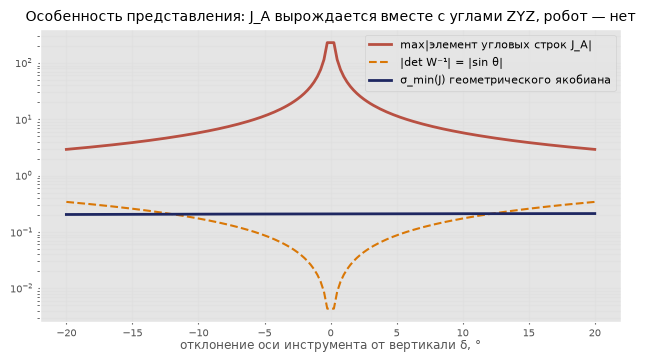

In [5]:
BREAK = False
import roboticstoolbox as rtb
Rxa = Rotation.from_euler('x', 90, degrees=True).as_matrix(); Rya = Rotation.from_euler('y', 90, degrees=True).as_matrix()
v_xy, v_yx = so3_log(Rya @ Rxa), so3_log(Rxa @ Rya)          # повороты вокруг неподвижных осей: левое умножение
print('сначала x, затем y: αk =', v_xy.round(3), '   сначала y, затем x: αk =', v_yx.round(3))
check('вектор поворота «x, затем y», третья компонента', v_xy[2], '−1,209'); check('вектор поворота «y, затем x», третья компонента', v_yx[2], '1,209')

ur = make_ur5e()
q = Q33.copy()
if BREAK:
    q[3] = -np.pi / 2 - (q[1] + q[2]); q[4] = np.pi / 2 + np.radians(0.5)   # ось инструмента в 0,5° от вертикали
def f(qq):
    TT = ur.forward(qq.copy()); return np.r_[TT.euler_zyz, TT.t_3_1.ravel()]
f0 = f(q)
JA_fd = np.column_stack([(f(q + 1e-6 * e) - f0) / 1e-6 for e in np.eye(6)])   # односторонние разности
ur.forward(q.copy()); J = ur.jacobian_book()
phi, th, psi = f0[:3]
Winv = np.array([[0, -np.sin(phi), np.cos(phi) * np.sin(th)], [0, np.cos(phi), np.sin(phi) * np.sin(th)], [1, 0, np.cos(th)]])
W = np.linalg.inv(Winv)
JA = blk(W, E3) @ J
print('углы ZYZ схвата (φ, θ, ψ) =', f0[:3].round(3), 'рад;  det W⁻¹ = −sin θ = %.4f' % np.linalg.det(Winv))
print('max|∂f/∂q − J| по угловым строкам = %.3f, по линейным = %.1e' % (np.abs(JA_fd[:3] - J[:3]).max(), np.abs(JA_fd[3:] - J[3:]).max()))
print('max|∂f/∂q − diag(W,E)·J| = %.1e' % np.abs(JA_fd - JA).max())
rob = rtb.DHRobot([rtb.RevoluteDH(d=d, a=a_, alpha=al, offset=th_) for d, a_, al, th_ in UR5E_DH])
print('rtb.jacob0_analytical(eul) после перестановки блоков против diag(W,E)·J: %.1e' % np.abs(vw_to_wv(rob.jacob0_analytical(q, representation='eul')) - JA).max())
if not BREAK:
    print('Сверка с конспектом:')
    for i, s in enumerate(('−1,893', '1,030', '1,349')):
        check('угол ZYZ %s' % 'φθψ'[i], f0[i], s, 'рад')
    check('max расхождение угловых строк ∂f/∂q и J_ω', np.abs(JA_fd[:3] - J[:3]).max(), '1,54')
    check_small('max|∂f/∂q − diag(W,E)J|', np.abs(JA_fd - JA).max(), '4e-7')
else:
    print('СЛОМАНО: max|J_A| = %.1f при σ_min(J) = %.3f' % (np.abs(JA).max(), svals(J)[-1]))

# особенность представления: q4 = −π/2 − (q2 + q3), q5 = π/2 + δ  ->  ось инструмента отклонена от вертикали на |δ|
ds = np.radians(np.linspace(-20, 20, 161)); ds = ds[np.abs(ds) > 1e-9]
sth, jam, smin = [], [], []
for d in ds:
    qq = Q33.copy(); qq[3] = -np.pi / 2 - (qq[1] + qq[2]); qq[4] = np.pi / 2 + d
    TT = ur.forward(qq.copy()); Jg = ur.jacobian_book(); ph, t_, _ = TT.euler_zyz
    Wi = np.array([[0, -np.sin(ph), np.cos(ph) * np.sin(t_)], [0, np.cos(ph), np.sin(ph) * np.sin(t_)], [1, 0, np.cos(t_)]])
    sth.append(abs(np.sin(t_))); jam.append(np.abs(np.linalg.solve(Wi, Jg[:3])).max()); smin.append(svals(Jg)[-1])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.semilogy(np.degrees(ds), jam, color=RED, lw=2, label='max|элемент угловых строк J_A|')
ax.semilogy(np.degrees(ds), sth, color=AMB, lw=1.5, ls='--', label='|det W⁻¹| = |sin θ|')
ax.semilogy(np.degrees(ds), smin, color=NAVY, lw=2, label='σ_min(J) геометрического якобиана')
ax.set_xlabel('отклонение оси инструмента от вертикали δ, °'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8)
ax.set_title('Особенность представления: J_A вырождается вместе с углами ZYZ, робот — нет', fontsize=10); plt.show()

## Демонстрация 5. Ошибка ориентации при конечном повороте (§ 3.4)

Формула (3.59) $\delta\boldsymbol\varphi=\frac12(\mathbf x_1\times\mathbf x_2+\mathbf y_1\times\mathbf y_2+\mathbf z_1\times\mathbf z_2)$ выведена для малых поворотов. Проверим на настоящих матрицах: для $R_2R_1^{\mathrm T}=\operatorname{Rot}(\mathbf k,\alpha)$ она даёт ровно $\sin\alpha\,\mathbf k$; удвоенная векторная часть кватерниона ошибки даёт $2\sin(\alpha/2)\,\mathbf k$; вектор поворота $\log(R_2R_1^{\mathrm T})^{\vee}=\alpha\mathbf k$ точен.

Затем замкнём контур: схват поворачивается с угловой скоростью $\boldsymbol\omega=K\mathbf e$, где $\mathbf e$ — ошибка ориентации по одной из трёх формул, $K=1$ с⁻¹, начальное рассогласование $179^\circ$. Интегрируем $\dot R=\Lambda(\boldsymbol\omega)R$ точным шагом $R\leftarrow\exp(\Lambda(\boldsymbol\omega)\Delta t)R$ и засекаем время до $1^\circ$.

**Сломай и посмотри** (`BREAK = True`): начальное рассогласование ровно $180^\circ$. Формула (3.59) даёт нулевую ошибку, и контур «не видит» рассогласования вовсе.

max| |(3.59)| − sin α | = 6.7e-16;  max| |кватернион| − 2 sin(α/2) | = 4.4e-16
направление (3.59) при 150° совпадает с осью k: True

 α, °   (3.59)   кватернион   вектор поворота, рад
  30    0.500        0.518        0.524
  90    1.000        1.414        1.571
 150    0.500        1.932        2.618
 179    0.017        2.000        3.124
Сверка с конспектом:
  совпадает   (3.59) при 30°: расчёт 0.5000, конспект 0,500 
  совпадает   кватернион при 30°: расчёт 0.5176, конспект 0,518 
  совпадает   вектор поворота при 30°: расчёт 0.5236, конспект 0,524 
  совпадает   (3.59) при 90°: расчёт 1.0000, конспект 1,000 
  совпадает   кватернион при 90°: расчёт 1.4142, конспект 1,414 
  совпадает   вектор поворота при 90°: расчёт 1.5708, конспект 1,571 
  совпадает   (3.59) при 150°: расчёт 0.5000, конспект 0,500 
  совпадает   кватернион при 150°: расчёт 1.9319, конспект 1,932 
  совпадает   вектор поворота при 150°: расчёт 2.6180, конспект 2,618 
  совпадает   (3.59) при 179°: расчёт 0.0175

(3.59)           время от 179° до 1°: 9.48 с
кватернион       время от 179° до 1°: 5.42 с
вектор поворота  время от 179° до 1°: 5.18 с
  совпадает   контур с (3.59): расчёт 9.48, конспект 9,5 с
  совпадает   контур с вектором поворота: расчёт 5.18, конспект 5,2 с


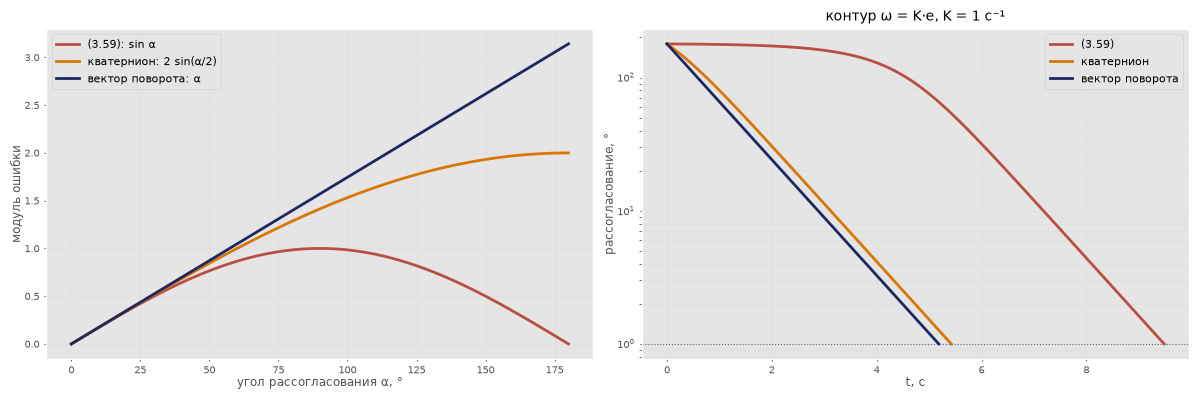

In [6]:
BREAK = False
rng = np.random.default_rng(1)
R1 = Rotation.random(random_state=1).as_matrix()
k = np.array([0.3, -0.5, 0.8]); k /= np.linalg.norm(k)
def e359(Ra, Rb):            # формула (3.59): ½Σ (орт Ra) × (орт Rb)
    return 0.5 * sum(np.cross(Ra[:, i], Rb[:, i]) for i in range(3))
def equat(Ra, Rb):           # удвоенная векторная часть кватерниона ошибки (скалярная часть ≥ 0)
    x, y, z, w_ = Rotation.from_matrix(Rb @ Ra.T).as_quat()
    return 2 * np.sign(w_ if w_ != 0 else 1) * np.array([x, y, z])
def elog(Ra, Rb):            # вектор поворота log(Rb Raᵀ)^∨
    return so3_log(Rb @ Ra.T)
al = np.radians(np.linspace(0, 180, 361)); n59, nq, nl = [], [], []
for a_ in al:
    R2 = so3_exp(a_ * k) @ R1
    n59.append(np.linalg.norm(e359(R1, R2))); nq.append(np.linalg.norm(equat(R1, R2))); nl.append(np.linalg.norm(elog(R1, R2)))
n59, nq, nl = map(np.array, (n59, nq, nl))
print('max| |(3.59)| − sin α | = %.1e;  max| |кватернион| − 2 sin(α/2) | = %.1e' % (np.abs(n59 - np.sin(al)).max(), np.abs(nq - 2 * np.sin(al / 2)).max()))
R2 = so3_exp(np.radians(150) * k) @ R1
print('направление (3.59) при 150° совпадает с осью k:', np.allclose(e359(R1, R2) / np.linalg.norm(e359(R1, R2)), k))
print('\n α, °   (3.59)   кватернион   вектор поворота, рад')
table = {30: ('0,500', '0,518', '0,524'), 90: ('1,000', '1,414', '1,571'), 150: ('0,500', '1,932', '2,618'), 179: ('0,017', '2,000', '3,124')}
for d in table:
    i = int(d * 2); print('%4d   %6.3f   %10.3f   %10.3f' % (d, n59[i], nq[i], nl[i]))
print('Сверка с конспектом:')
for d, (s1, s2, s3) in table.items():
    i = int(d * 2); check('(3.59) при %d°' % d, n59[i], s1); check('кватернион при %d°' % d, nq[i], s2); check('вектор поворота при %d°' % d, nl[i], s3)

def contour(err, a0, K=1.0, dt=0.002, a_end=np.radians(1.0), t_max=40.0):
    Rs = np.eye(3); Rc = so3_exp(a0 * k)               # цель R* = E, текущая ориентация Rc
    t, ts, angs = 0.0, [0.0], [a0]
    while t < t_max:
        om = K * err(Rc, Rs)                          # ω = K e, e переводит Rc в R*
        Rc = so3_exp(om * dt) @ Rc; t += dt
        ang = np.linalg.norm(so3_log(Rc)); ts.append(t); angs.append(ang)
        if ang <= a_end: break
    return np.array(ts), np.degrees(angs)
a0 = np.radians(180.0 if BREAK else 179.0)
res = {name: contour(fn, a0) for name, fn in (('(3.59)', e359), ('кватернион', equat), ('вектор поворота', elog))}
for name, (ts, ang) in res.items():
    print('%-16s время от %.0f° до 1°: %s' % (name, np.degrees(a0), ('%.2f с' % ts[-1]) if ang[-1] <= 1.0 + 1e-9 else 'не дошёл за %.0f с (угол %.1f°)' % (ts[-1], ang[-1])))
if not BREAK:
    check('контур с (3.59)', res['(3.59)'][0][-1], '9,5', 'с'); check('контур с вектором поворота', res['вектор поворота'][0][-1], '5,2', 'с')

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(np.degrees(al), n59, color=RED, lw=2, label='(3.59): sin α')
axs[0].plot(np.degrees(al), nq, color=AMB, lw=2, label='кватернион: 2 sin(α/2)')
axs[0].plot(np.degrees(al), nl, color=NAVY, lw=2, label='вектор поворота: α')
axs[0].set_xlabel('угол рассогласования α, °'); axs[0].set_ylabel('модуль ошибки'); axs[0].grid(alpha=.3); axs[0].legend(fontsize=8)
for (name, (ts, ang)), col in zip(res.items(), (RED, AMB, NAVY)):
    axs[1].plot(ts, ang, color=col, lw=2, label=name)
axs[1].axhline(1, color=GREY, lw=.8, ls=':'); axs[1].set_yscale('log'); axs[1].set_xlabel('t, с'); axs[1].set_ylabel('рассогласование, °')
axs[1].grid(alpha=.3, which='both'); axs[1].legend(fontsize=8); axs[1].set_title('контур ω = K·e, K = 1 с⁻¹', fontsize=10)
plt.tight_layout(); plt.show()

## Демонстрация 6. Двухзвенник у границы зоны (§ 3.5, примеры 3.2 и 3.4)

Двухзвенник $l_1=l_2=1$ м, ветвь $q_2>0$ («локоть вниз» в осях курса). Схват идёт вдоль оси $x$ к границе зоны $r=2$ со скоростью 0,1 м/с. Скорости сочленений растут как $1/\sigma_{\min}$, причём только для радиального («потерянного») направления; команда поперёк руки в тех же позах требует малых скоростей. Из $r=2\cos(q_2/2)$ следует $\dot q_2=-\dot r/\sin(q_2/2)\sim1/\sqrt{t^\ast-t}$: граница достигается за конечное время, наклон графика в логарифмических осях равен $-1/2$.

Демпфированное псевдообращение $J_\mu^{+}=J^{\mathrm T}(JJ^{\mathrm T}+\mu^2E)^{-1}$ ограничивает скорости сочленений, но платит точностью: схват движется медленнее команды. В самих особых точках проверим семейства решений примера 3.2 (вытянутая $q_2=0$ и сложенная $q_2=\pi$ рука) и формулы примера 3.4: $J_v^{+}=J_v^{\mathrm T}/(5a^2)$ и $J_v^{\mathrm T}/a^2$.

**Сломай и посмотри** (`BREAK = True`): семейство решений в особой точке берётся в книжной форме $\dot q_2=-2t-\lvert\mathbf v\rvert/a$. Для сложенной руки и для одного из двух направлений скорости у вытянутой руки невязка становится конечной.

  x, м    q1, °    q2, °   ‖q̇‖ радиально   ‖q̇‖ поперёк   σ_min
 1.000   -60.00   120.00           0.129         0.100    0.707
 1.400   -45.57    91.15           0.157         0.071    0.624
 1.800   -25.84    51.68           0.256         0.056    0.388
 1.900   -18.19    36.39           0.358         0.053    0.279
 1.950   -12.84    25.68           0.503         0.051    0.199
 1.990    -5.73    11.46           1.119         0.050    0.089
 1.999    -1.81     3.62           3.536         0.050    0.028
Сверка с конспектом:
  совпадает   ‖q̇‖ при x = 1,0 м: расчёт 0.1291, конспект 0,129 рад/с
  совпадает   ‖q̇‖ при x = 1,9 м: расчёт 0.3581, конспект 0,358 рад/с
  совпадает   ‖q̇‖ при x = 1,99 м: расчёт 1.119, конспект 1,12 рад/с
  совпадает   ‖q̇‖ при x = 1,999 м: расчёт 3.536, конспект 3,54 рад/с
  совпадает   DLS μ = 0,05: ‖q̇‖ при x = 1,99: расчёт 0.8523, план демонстраций 0,852 рад/с
  совпадает   DLS μ = 0,05: реализуемая скорость: расчёт 0.0761, план демонстраций 0,076 м/с
  

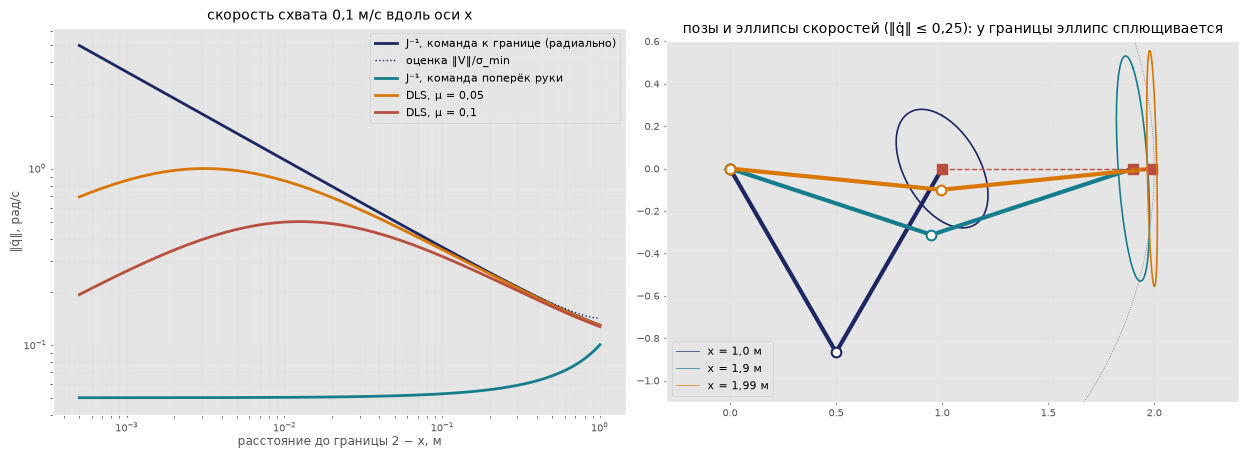

In [7]:
BREAK = False
l = (1.0, 1.0); a = 1.0
v_rad, v_tan = np.array([0.1, 0.0]), np.array([0.0, 0.1])
print('  x, м    q1, °    q2, °   ‖q̇‖ радиально   ‖q̇‖ поперёк   σ_min')
res = {}
for x in (1.0, 1.4, 1.8, 1.9, 1.95, 1.99, 1.999):
    qx = ik2r(x, 0.0, l)[0]                          # первая ветвь ik2r: q2 > 0, «локоть вниз»
    Jx = jac2r(qx, l)
    nr, nt = np.linalg.norm(np.linalg.solve(Jx, v_rad)), np.linalg.norm(np.linalg.solve(Jx, v_tan))
    res[x] = nr
    print('%6.3f  %7.2f  %7.2f  %14.3f  %12.3f  %7.3f' % (x, *np.degrees(qx), nr, nt, svals(Jx)[-1]))
print('Сверка с конспектом:')
for x, s in ((1.0, '0,129'), (1.9, '0,358'), (1.99, '1,12'), (1.999, '3,54')):
    check('‖q̇‖ при x = %s м' % str(x).replace('.', ','), res[x], s, 'рад/с')
qx = ik2r(1.99, 0.0, l)[0]; Jx = jac2r(qx, l)
for mu, sn, sv in ((0.05, '0,852', '0,076'), (0.1, '0,497', '0,044')):
    qd = Jx.T @ np.linalg.solve(Jx @ Jx.T + mu ** 2 * np.eye(2), v_rad)
    check('DLS μ = %s: ‖q̇‖ при x = 1,99' % str(mu).replace('.', ','), np.linalg.norm(qd), sn, 'рад/с', src='план демонстраций')
    check('DLS μ = %s: реализуемая скорость' % str(mu).replace('.', ','), (Jx @ qd)[0], sv, 'м/с', src='план демонстраций')

# время до границы: x(t) = 1 + 0,1 t, t* = 10 с
tt = 10 - np.logspace(-4, 0.9, 200); q2d = []
for t in tt:
    qx = ik2r(1 + 0.1 * t, 0.0, l)[0]; q2d.append(abs(np.linalg.solve(jac2r(qx, l), v_rad)[1]))
slope = np.polyfit(np.log(10 - tt[:80]), np.log(q2d[:80]), 1)[0]
print('наклон log|q̇₂| по log(t* − t) у границы: %.3f (теория −1/2)' % slope)

# семейства решений в особых точках (пример 3.2) и псевдообратная (пример 3.4)
q1 = 0.4; s1, c1 = np.sin(q1), np.cos(q1); n_perp = np.array([-s1, c1])
for q2, name in ((0.0, 'вытянутая'), (np.pi, 'сложенная')):
    Jq = jac2r((q1, q2), l); worst = 0.0
    for vp in (0.1, -0.1):
        v = vp * n_perp
        for t in (-1.0, 0.0, 0.7):
            if BREAK:
                qd = np.array([t, -2 * t - np.linalg.norm(v) / a])                 # книжная форма
            else:
                qd = np.array([t, vp / a - 2 * t]) if q2 == 0 else np.array([t, -vp / a])
            worst = max(worst, np.linalg.norm(Jq @ qd - v))
    print('%s рука: max невязка семейства решений %s = %.1e' % (name, '(книжная форма, СЛОМАНО)' if BREAK else '', worst))
print('пример 3.4: max|J⁺ − Jᵀ/(5a²)| = %.1e (q2 = 0),  max|J⁺ − Jᵀ/a²| = %.1e (q2 = π)' % (
    np.abs(np.linalg.pinv(jac2r((q1, 0.0), l)) - jac2r((q1, 0.0), l).T / 5).max(), np.abs(np.linalg.pinv(jac2r((q1, np.pi), l)) - jac2r((q1, np.pi), l).T).max()))

xs = 2 - np.logspace(-3.3, 0, 300)
nr, nt, nd1, nd2, bnd = [], [], [], [], []
for x in xs:
    Jx = jac2r(ik2r(x, 0.0, l)[0], l)
    nr.append(np.linalg.norm(np.linalg.solve(Jx, v_rad))); nt.append(np.linalg.norm(np.linalg.solve(Jx, v_tan)))
    for mu, lst in ((0.05, nd1), (0.1, nd2)):
        lst.append(np.linalg.norm(Jx.T @ np.linalg.solve(Jx @ Jx.T + mu ** 2 * np.eye(2), v_rad)))
    bnd.append(0.1 / svals(Jx)[-1])
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axs[0]
ax.loglog(2 - xs, nr, color=NAVY, lw=2, label='J⁻¹, команда к границе (радиально)')
ax.loglog(2 - xs, bnd, color=NAVY, lw=1, ls=':', label='оценка ‖V‖/σ_min')
ax.loglog(2 - xs, nt, color=TEAL, lw=2, label='J⁻¹, команда поперёк руки')
ax.loglog(2 - xs, nd1, color=AMB, lw=2, label='DLS, μ = 0,05'); ax.loglog(2 - xs, nd2, color=RED, lw=2, label='DLS, μ = 0,1')
ax.set_xlabel('расстояние до границы 2 − x, м'); ax.set_ylabel('‖q̇‖, рад/с'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8)
ax.set_title('скорость схвата 0,1 м/с вдоль оси x', fontsize=10)
ax = axs[1]
for x, col in ((1.0, NAVY), (1.9, TEAL), (1.99, AMB)):
    qx = ik2r(x, 0.0, l)[0]; pts = draw_arm2d(ax, qx, l, color=col, lw=3)
    e = ellipse_image(jac2r(qx, l), 0.25); ax.plot(pts[-1, 0] + e[:, 0], pts[-1, 1] + e[:, 1], color=col, lw=1.2)
    ax.plot([], [], color=col, label='x = %s м' % str(x).replace('.', ','))
ax.plot([1, 2], [0, 0], color=RED, lw=1, ls='--'); ax.add_patch(plt.Circle((0, 0), 2, fill=False, color=GREY, ls=':'))
ax.set_aspect('equal'); ax.set_xlim(-0.3, 2.4); ax.set_ylim(-1.1, 0.6); ax.grid(alpha=.3); ax.legend(fontsize=8, loc='lower left')
ax.set_title('позы и эллипсы скоростей (‖q̇‖ ≤ 0,25): у границы эллипс сплющивается', fontsize=10)
plt.tight_layout(); plt.show()

## Демонстрация 7. Особые конфигурации шестизвенников (§ 3.6–3.7, примеры 3.3 и 3.3а)

**PUMA 560** в расстановке осей лекций (`make_puma('book')`, примеры 2.4 и 3.3). На случайных конфигурациях проверяем: определитель подсистемы «несущих» сочленений $D_{123}=a_2y_{34}x_{14}$; величина $y_{34}=a_3s_3-d_4c_3$ — проекция на ось $y_2$ вектора $O_2O_4$ (от оси локтя к центру запястья), а не $O_3O_4$; $x_{14}$ — плечо поворота $q_1$, а горизонтальное расстояние центра запястья до оси $z_0$ равно $\sqrt{x_{14}^2+d_2^2}$; определитель запястья $D_{456}=-s_5$; явные формулы $\dot q_1\dots\dot q_6$ совпадают с численным решением. Затем находим три семейства особых конфигураций и сверяем модель с Robotics Toolbox (`Puma560`).

**UR5e.** Символьный определитель по столбцам (3.62) (sympy, около 20 с) даёт формулу примера 3.3а. Кистевая особенность: команда 0,1 м/с вдоль $x_0$ без вращения в конфигурации раздела 3.3 с малым $q_5$. Сравниваем точное обращение и DLS с $\mu=0{,}05$ и показываем разрыв $J^{+}$ в самой особой точке: на сетке $q_5$, содержащей нуль, норма $\lVert J^{+}\boldsymbol{\mathcal V}\rVert$ проваливается до 0,35 рад/с, потому что $J^{+}$ отбрасывает потерянное направление вместе с частью команды (невязка 22 %).

**Сломай и посмотри** (`BREAK = True`): явные формулы запястья PUMA (3.108)–(3.110) вычисляются ровно при $q_5=0$ — деление на $s_5=0$ даёт `inf`/`nan`, хотя `numpy.linalg.pinv` спокойно возвращает конечный (но неточный) ответ.

In [8]:
BREAK = False
import roboticstoolbox as rtb
from scipy.optimize import brentq
pu = make_puma('book')
d2, a2, a3, d4 = 0.15005, 0.4318, 0.0203, 0.4318
def puma_frames(q):
    pu.forward(np.asarray(q, float).copy()); Ts = [np.eye(4)] + [f.t_4_4 for f in pu.axis_frames]
    return [T[:3, 0] for T in Ts], [T[:3, 1] for T in Ts], [T[:3, 2] for T in Ts], [T[:3, 3] for T in Ts]
rng = np.random.default_rng(3); worst = dict(D123=0, y34=0, y34_O3=np.inf, dist=0, D456=0, qd=0)
for trial in range(5):
    q = rng.uniform(-1.5, 1.5, 6)
    if BREAK and trial == 0: q[4] = 0.0
    x, y, z, o = puma_frames(q)
    s3, c3, c2, c23, s23 = np.sin(q[2]), np.cos(q[2]), np.cos(q[1]), np.cos(q[1] + q[2]), np.sin(q[1] + q[2])
    y34, x14 = a3 * s3 - d4 * c3, a2 * c2 + a3 * c23 + d4 * s23
    p04 = o[4] - o[0]
    D123 = np.linalg.det(np.column_stack([np.cross(z[0], o[4] - o[0]), np.cross(z[1], o[4] - o[1]), np.cross(z[2], o[4] - o[2])]))
    worst['D123'] = max(worst['D123'], abs(D123 - a2 * y34 * x14))
    worst['y34'] = max(worst['y34'], abs(y34 - (o[4] - o[2]) @ y[2])); worst['y34_O3'] = min(worst['y34_O3'], abs(y34 - (o[4] - o[3]) @ y[2]))
    worst['dist'] = max(worst['dist'], abs(np.hypot(o[4][0], o[4][1]) - np.hypot(x14, d2)))
    worst['D456'] = max(worst['D456'], abs(np.linalg.det(np.column_stack([z[3], z[4], z[5]])) + np.sin(q[4])))
    w_, v_ = rng.normal(size=3), rng.normal(size=3)
    Jp = pu.jacobian_book(); qd_num = np.linalg.pinv(Jp) @ np.r_[w_, v_]
    v4 = v_ - np.cross(w_, o[6] - o[4])                          # скорость центра запястья
    qd1 = v4 @ z[2] / x14
    qd2 = v4 @ (d2 * (a3 * c23 + d4 * s23) * z[1] + x14 * a3 * x[3] + x14 * d4 * z[3]) / (a2 * y34 * x14)
    qd3 = -(v4 @ p04) / (a2 * y34)
    ww = w_ - z[0] * qd1 - z[1] * qd2 - z[2] * qd3                # ω_w — часть, которую отрабатывает запястье
    with np.errstate(divide='ignore', invalid='ignore'):
        s5 = np.sin(q[4]); qd456 = np.array([-(ww @ x[5]) / s5, ww @ z[4], (ww @ x[4]) / s5])
    if BREAK and trial == 0:
        print('СЛОМАНО: q5 = 0, формулы запястья дают', qd456, ', а pinv —', qd_num[3:].round(3), '(невязка %.2f)' % np.linalg.norm(Jp @ qd_num - np.r_[w_, v_]))
        continue
    worst['qd'] = max(worst['qd'], np.abs(np.r_[qd1, qd2, qd3, qd456] - qd_num).max())
print('PUMA, 5 случайных конфигураций:')
print('  max|D123 − a2·y34·x14| = %.1e;  max|y34 − (O4 − O2)·y2| = %.1e;  min|y34 − (O4 − O3)·y2| = %.4f (это не O3O4)' % (worst['D123'], worst['y34'], worst['y34_O3']))
print('  max|горизонтальное расстояние O4 до z0 − √(x14² + d2²)| = %.1e;  max|D456 + s5| = %.1e' % (worst['dist'], worst['D456']))
print('  max|формулы (3.101)–(3.110) − численное решение| = %.1e' % worst['qd'])

# три семейства особенностей PUMA
q = np.array([0.3, -0.5, 1.2, 0.4, 0.8, 0.2])
qe = q.copy(); qe[2] = np.arctan2(d4, a3)                          # y34 = 0: локоть
x14f = lambda t: a2 * np.cos(t) + a3 * np.cos(t + q[2]) + d4 * np.sin(t + q[2])
qs = q.copy(); qs[1] = brentq(x14f, -np.pi / 2, np.pi / 2)        # x14 = 0: плечо
qw = q.copy(); qw[4] = 0.0                                        # s5 = 0: кисть
for name, qq in (('общая поза', q), ('локоть, y34 = 0', qe), ('плечо, x14 = 0', qs), ('кисть, q5 = 0', qw)):
    x, y, z, o = puma_frames(qq)
    print('  %-17s σ_min(J) = %.1e, расстояние центра запястья до оси z0 = %.4f м' % (name, svals(pu.jacobian_book())[-1], np.hypot(o[4][0], o[4][1])))
print('  (в плечевой особенности расстояние равно d2 = %.5f м: цилиндр радиуса d2, а не ось)' % d2)
pu.forward(qw.copy()); Jw = pu.jacobian_book(); Jwp = np.linalg.pinv(Jw, rcond=1e-10)
alpha_best = np.sum(Jwp * Jw.T) / np.sum(Jw.T * Jw.T)
print('  при q5 = 0 ранг J = %d; лучшее приближение J⁺ ≈ αJᵀ даёт относительную ошибку %.2f — пропорциональности нет' % (
    np.linalg.matrix_rank(Jw, tol=1e-10), np.linalg.norm(Jwp - alpha_best * Jw.T) / np.linalg.norm(Jwp)))

# сверка kinlib.make_puma('rtb') с Robotics Toolbox
p560, pr = rtb.models.DH.Puma560(), make_puma('rtb'); dmax = 0.0
for _ in range(5):
    qq = rng.uniform(-1.5, 1.5, 6); pr.forward(qq.copy()); dmax = max(dmax, np.abs(p560.jacob0(qq) - pr.jacobian).max())
qq = np.array([0.2, -0.4, 0.3, 0.5, 0.0, 0.1])
print('Robotics Toolbox Puma560: max|jacob0 − make_puma(\'rtb\').jacobian| = %.1e; при q5 = 0 σ_min(jacob0) = %.1e' % (dmax, svals(p560.jacob0(qq))[-1]))

PUMA, 5 случайных конфигураций:
  max|D123 − a2·y34·x14| = 4.2e-17;  max|y34 − (O4 − O2)·y2| = 5.6e-17;  min|y34 − (O4 − O3)·y2| = 0.0017 (это не O3O4)
  max|горизонтальное расстояние O4 до z0 − √(x14² + d2²)| = 1.1e-16;  max|D456 + s5| = 3.3e-16
  max|формулы (3.101)–(3.110) − численное решение| = 1.8e-14
  общая поза        σ_min(J) = 5.5e-02, расстояние центра запястья до оси z0 = 0.6892 м
  локоть, y34 = 0   σ_min(J) = 2.1e-17, расстояние центра запястья до оси z0 = 0.7730 м
  плечо, x14 = 0    σ_min(J) = 2.6e-16, расстояние центра запястья до оси z0 = 0.1500 м
  кисть, q5 = 0     σ_min(J) = 1.3e-17, расстояние центра запястья до оси z0 = 0.6892 м
  (в плечевой особенности расстояние равно d2 = 0.15005 м: цилиндр радиуса d2, а не ось)
  при q5 = 0 ранг J = 5; лучшее приближение J⁺ ≈ αJᵀ даёт относительную ошибку 0.98 — пропорциональности нет
Robotics Toolbox Puma560: max|jacob0 − make_puma('rtb').jacobian| = 2.2e-16; при q5 = 0 σ_min(jacob0) = 1.2e-17


In [9]:
import sympy as sp
t_start = time.time()
q2s, q3s, q4s, q5s = sp.symbols('q2 q3 q4 q5'); a2s, a3s, d1s, d4s, d5s, d6s = sp.symbols('a_2 a_3 d_1 d_4 d_5 d_6')
qsym = [0, q2s, q3s, q4s, q5s, 0]            # det J не зависит от q1 и q6 — подставляем нули сразу
dh_sym = [(d1s, 0, sp.pi / 2), (0, a2s, 0), (0, a3s, 0), (d4s, 0, sp.pi / 2), (d5s, 0, -sp.pi / 2), (d6s, 0, 0)]
def A_sym(d, a, al, th):
    ca, sa = sp.cos(al), sp.sin(al)
    return sp.Matrix([[sp.cos(th), -sp.sin(th) * ca, sp.sin(th) * sa, a * sp.cos(th)], [sp.sin(th), sp.cos(th) * ca, -sp.cos(th) * sa, a * sp.sin(th)], [0, sa, ca, d], [0, 0, 0, 1]])
Ts = [sp.eye(4)]
for i in range(6):
    Ts.append((Ts[-1] * A_sym(*dh_sym[i], qsym[i])).applyfunc(sp.trigsimp))
pNs = Ts[6][:3, 3]
Jsym = sp.Matrix.hstack(*[sp.Matrix.vstack(Ts[i][:3, 2], Ts[i][:3, 2].cross(pNs - Ts[i][:3, 3])) for i in range(6)])
detJ = sp.factor(sp.trigsimp(sp.expand_trig(sp.simplify(Jsym.det(method='berkowitz')))))
display(sp.Eq(sp.Symbol(r'\det J'), detJ))
print('символьный расчёт занял %.0f с' % (time.time() - t_start))
ur = make_ur5e(); ur.forward(Q33.copy())
a2n, a3n, d5n = UR5E_DH[1, 1], UR5E_DH[2, 1], UR5E_DH[4, 0]
qn = Q33
formula = -a2n * a3n * np.sin(qn[2]) * np.sin(qn[4]) * (a2n * np.cos(qn[1]) + a3n * np.cos(qn[1] + qn[2]) + d5n * np.sin(qn[1] + qn[2] + qn[3]))
print('конфигурация раздела 3.3: det J численно = %.4f, по формуле = %.4f' % (np.linalg.det(ur.jacobian_book()), formula))
print('Сверка с конспектом:')
check('det J UR5e численно', np.linalg.det(ur.jacobian_book()), '0,0719'); check('det J UR5e по формуле', formula, '0,0719');

Eq(\det J, -a_2*a_3*(a_2*cos(q2) + a_3*cos(q2 + q3) + d_5*sin(q2 + q3 + q4))*sin(q3)*sin(q5))

символьный расчёт занял 21 с
конфигурация раздела 3.3: det J численно = 0.0719, по формуле = 0.0719
Сверка с конспектом:
  совпадает   det J UR5e численно: расчёт 0.07187, конспект 0,0719 
  совпадает   det J UR5e по формуле: расчёт 0.07187, конспект 0,0719 


кистевая особенность UR5e (конфигурация раздела 3.3 с малым q5), J⁻¹V:
  q5 = 2.0°: q̇ = [ 0.048 -0.08  -0.073  1.148  0.034 -0.996]
  совпадает   q̇4 при q5 = 2,0°: расчёт 1.148, конспект 1,15 рад/с
  совпадает   q̇6 при q5 = 2,0°: расчёт -0.996, конспект −1,00 рад/с
  q5 = 1.0°: q̇ = [ 0.048  0.048 -0.437  2.381  0.034 -1.992]
  совпадает   q̇4 при q5 = 1,0°: расчёт 2.381, конспект 2,38 рад/с
  совпадает   q̇6 при q5 = 1,0°: расчёт -1.992, конспект −1,99 рад/с
  q5 = 0.5°: q̇ = [ 0.048  0.304 -1.167  4.846  0.034 -3.983]
  совпадает   q̇4 при q5 = 0,5°: расчёт 4.846, конспект 4,85 рад/с
  совпадает   q̇6 при q5 = 0,5°: расчёт -3.983, конспект −3,98 рад/с
  совпадает   предел π рад/с нарушается ближе, чем q5 =, при 0,1 м/с: расчёт 0.764, конспект 0,76 °
  совпадает   предел π рад/с нарушается ближе, чем q5 =, при 0,5 м/с: расчёт 3.46, конспект 3,5 °
  совпадает   q5 = 1°: ‖J⁻¹V‖: расчёт 3.136, конспект 3,14 рад/с
  совпадает   q5 = 1°: ‖DLS‖, μ = 0,05: расчёт 0.343, конспект 0,34 рад/

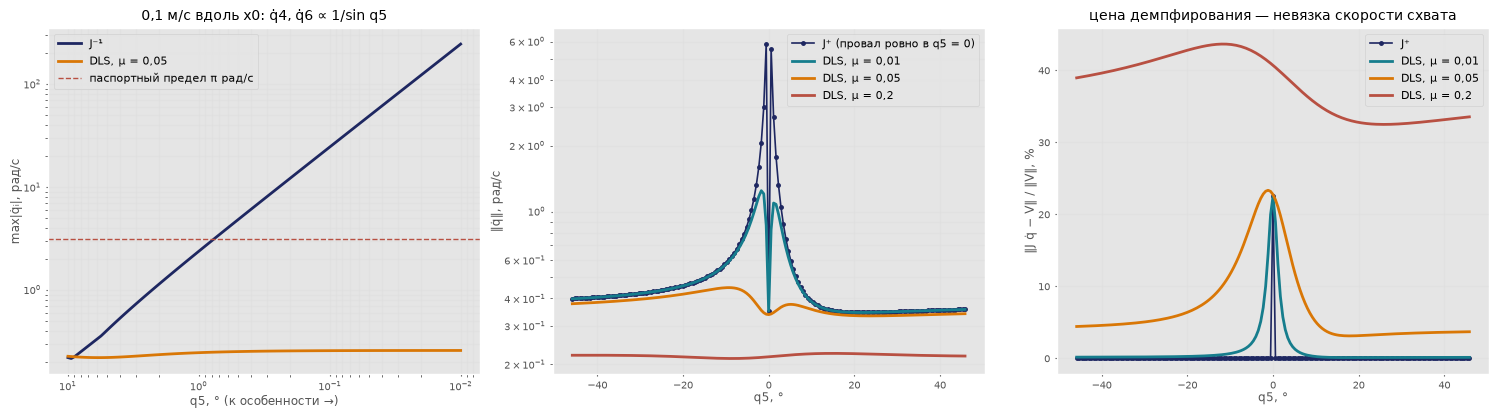

In [10]:
ur = make_ur5e(); V = np.array([0, 0, 0, 0.1, 0, 0])            # (ω; v): 0,1 м/с вдоль x0 без вращения
def Jq5(q5):
    qq = Q33.copy(); qq[4] = q5; ur.forward(qq); return ur.jacobian_book()
def dls(J, V, mu):
    return J.T @ np.linalg.solve(J @ J.T + mu ** 2 * np.eye(J.shape[0]), V)
print('кистевая особенность UR5e (конфигурация раздела 3.3 с малым q5), J⁻¹V:')
for d, s4, s6 in ((2.0, '1,15', '−1,00'), (1.0, '2,38', '−1,99'), (0.5, '4,85', '−3,98')):
    qd = np.linalg.solve(Jq5(np.radians(d)), V)
    print('  q5 = %.1f°: q̇ =' % d, qd.round(3))
    check('q̇4 при q5 = %s°' % str(d).replace('.', ','), qd[3], s4, 'рад/с'); check('q̇6 при q5 = %s°' % str(d).replace('.', ','), qd[5], s6, 'рад/с')
for spd, s in ((0.1, '0,76'), (0.5, '3,5')):
    q5_lim = brentq(lambda d: np.abs(np.linalg.solve(Jq5(np.radians(d)), V * spd / 0.1)).max() - np.pi, 0.05, 10.0)
    check('предел π рад/с нарушается ближе, чем q5 =, при %s м/с' % str(spd).replace('.', ','), q5_lim, s, '°')
J1 = Jq5(np.radians(1.0)); qe, qdl = np.linalg.solve(J1, V), dls(J1, V, 0.05)
check('q5 = 1°: ‖J⁻¹V‖', np.linalg.norm(qe), '3,14', 'рад/с'); check('q5 = 1°: ‖DLS‖, μ = 0,05', np.linalg.norm(qdl), '0,34', 'рад/с')
check('q5 = 1°: невязка DLS', 100 * np.linalg.norm(J1 @ qdl - V) / 0.1, '21', '%')
J0 = Jq5(0.0); qp0 = np.linalg.pinv(J0) @ V; qph = np.linalg.pinv(Jq5(np.radians(0.5))) @ V
check('q5 = 0: ‖J⁺V‖', np.linalg.norm(qp0), '0,35', 'рад/с'); check('q5 = 0: невязка J⁺', 100 * np.linalg.norm(J0 @ qp0 - V) / 0.1, '22,5', '%')
check('q5 = 0,5°: ‖J⁺V‖', np.linalg.norm(qph), '6,39', 'рад/с')

# развёртка: max|q̇| при q5 → 0 (лог. шкала) и разрыв J⁺ на сетке, содержащей нуль
q5l = np.radians(np.logspace(1, -2, 120)); m_inv, m_dls = [], []
for v5 in q5l:
    J = Jq5(v5); m_inv.append(np.abs(np.linalg.solve(J, V)).max()); m_dls.append(np.abs(dls(J, V, 0.05)).max())
q5g = np.linspace(-0.8, 0.8, 161); n_p, r_p, n_d, r_d = [], [], {m: [] for m in (0.01, 0.05, 0.2)}, {m: [] for m in (0.01, 0.05, 0.2)}
for v5 in q5g:
    J = Jq5(v5); qp = np.linalg.pinv(J) @ V; n_p.append(np.linalg.norm(qp)); r_p.append(np.linalg.norm(J @ qp - V) / 0.1)
    for m in n_d:
        qd = dls(J, V, m); n_d[m].append(np.linalg.norm(qd)); r_d[m].append(np.linalg.norm(J @ qd - V) / 0.1)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
axs[0].loglog(np.degrees(q5l), m_inv, color=NAVY, lw=2, label='J⁻¹'); axs[0].loglog(np.degrees(q5l), m_dls, color=AMB, lw=2, label='DLS, μ = 0,05')
axs[0].axhline(np.pi, color=RED, ls='--', lw=1, label='паспортный предел π рад/с'); axs[0].invert_xaxis()
axs[0].set_xlabel('q5, ° (к особенности →)'); axs[0].set_ylabel('max|q̇ᵢ|, рад/с'); axs[0].grid(alpha=.3, which='both'); axs[0].legend(fontsize=8)
axs[0].set_title('0,1 м/с вдоль x0: q̇4, q̇6 ∝ 1/sin q5', fontsize=10)
axs[1].semilogy(np.degrees(q5g), n_p, 'o-', ms=2.5, color=NAVY, lw=1.2, label='J⁺ (провал ровно в q5 = 0)')
for m, col in zip(n_d, (TEAL, AMB, RED)):
    axs[1].semilogy(np.degrees(q5g), n_d[m], color=col, lw=2, label='DLS, μ = %s' % str(m).replace('.', ','))
axs[1].set_xlabel('q5, °'); axs[1].set_ylabel('‖q̇‖, рад/с'); axs[1].grid(alpha=.3, which='both'); axs[1].legend(fontsize=8)
axs[2].plot(np.degrees(q5g), 100 * np.array(r_p), 'o-', ms=2.5, color=NAVY, lw=1.2, label='J⁺')
for m, col in zip(r_d, (TEAL, AMB, RED)):
    axs[2].plot(np.degrees(q5g), 100 * np.array(r_d[m]), color=col, lw=2, label='DLS, μ = %s' % str(m).replace('.', ','))
axs[2].set_xlabel('q5, °'); axs[2].set_ylabel('‖J q̇ − V‖ / ‖V‖, %'); axs[2].grid(alpha=.3); axs[2].legend(fontsize=8)
axs[2].set_title('цена демпфирования — невязка скорости схвата', fontsize=10)
plt.tight_layout(); plt.show()

## Демонстрация 8. Избыточный плоский трёхзвенник (§ 3.7, пример 3.4а)

Длины звеньев $1{,}0$; $0{,}8$; $0{,}6$ м, задано только положение схвата: два уравнения, три неизвестных, ядро $J$ одномерно. Общее решение $\dot{\mathbf q}=J^{+}\mathbf v+(E-J^{+}J)\boldsymbol\xi$.

* (а) Решение наименьшей нормы против другого решения из того же семейства — одна и та же скорость схвата.
* (б) Чистое самодвижение $\boldsymbol\xi=(0;0;1)$: без обратной связи по положению схват уплывает (явный Эйлер, дрейф пропорционален шагу), с коррекцией $\dot{\mathbf q}=J^{+}K(\mathbf p_0-\mathbf p)+(E-J^{+}J)\boldsymbol\xi$ (CLIK — closed-loop inverse kinematics) отклонение в десятки раз меньше и не накапливается: оно остаётся порядка шага, а не растёт со временем.
* (в) Пример 3.4а: уход от предела сочленения проекцией градиента $\boldsymbol\xi=k\nabla g$, $g=-\sum\big((q_i-\bar q_i)/\Delta q_i\big)^2$, пределы $\lvert q_i\rvert\le120^\circ$, старт $(30^\circ,20^\circ,100^\circ)$; интегрирование 5 с с $k=3$, $K=5$ с⁻¹, $\Delta t=0{,}01$ с.

**Сломай и посмотри** (`BREAK = True`): в части (в) убирается коррекция по положению ($K=0$) — схват уплывает от исходной точки.

(а) J⁺v = [-0.054 -0.068 -0.039]  ‖·‖ = 0.095;  другое решение [-0.023 -0.171  0.1  ]  ‖·‖ = 0.200;  J q̇ одинаково: True
    базис ядра J: [ 0.176 -0.588  0.789]
(б) без коррекции, 3 с, Δt = 0.05 с: дрейф схвата 5.0e-03 м


(б) без коррекции, 3 с, Δt = 0.005 с: дрейф схвата 5.0e-04 м
    с коррекцией K = 5 с⁻¹, Δt = 0.01 с: наибольшее отклонение 1.1e-04 м, через 3 с 1.6e-05 м (не накапливается, ∝ Δt)


    с коррекцией K = 5 с⁻¹, Δt = 0.001 с: наибольшее отклонение 1.1e-05 м, через 3 с 1.6e-06 м (не накапливается, ∝ Δt)
    конфигурация через 3 с самодвижения: [ 45.5 -21.2  74.4] °
(в) ∇g = [-0.239 -0.159 -0.796]   Pξ (k = 1) = [-0.151  0.317 -0.253]   J·Pξ = [ 0. -0.]   ġ = 0.187
    через 5 с: q = [ 7.4 69.  45.9] °, схват в [0.861 1.413] м, отклонение 2.1e-08 м
Сверка с конспектом:
  совпадает   ∇g, компонента 1: расчёт -0.2387, конспект −0,239 
  совпадает   ∇g, компонента 2: расчёт -0.1592, конспект −0,159 
  совпадает   ∇g, компонента 3: расчёт -0.7958, конспект −0,796 
  совпадает   Pξ, компонента 1: расчёт -0.1508, конспект −0,151 рад/с
  совпадает   Pξ, компонента 2: расчёт 0.3166, конспект 0,317 рад/с
  совпадает   Pξ, компонента 3: расчёт -0.2531, конспект −0,253 рад/с
  совпадает   ġ: расчёт 0.1870, конспект 0,187 
  совпадает   q1 через 5 с: расчёт 7.36, конспект 7,4 °
  совпадает   q2 через 5 с: расчёт 68.96, конспект 69,0 °
  совпадает   q3 через 5 с: расчёт 45.94, кон

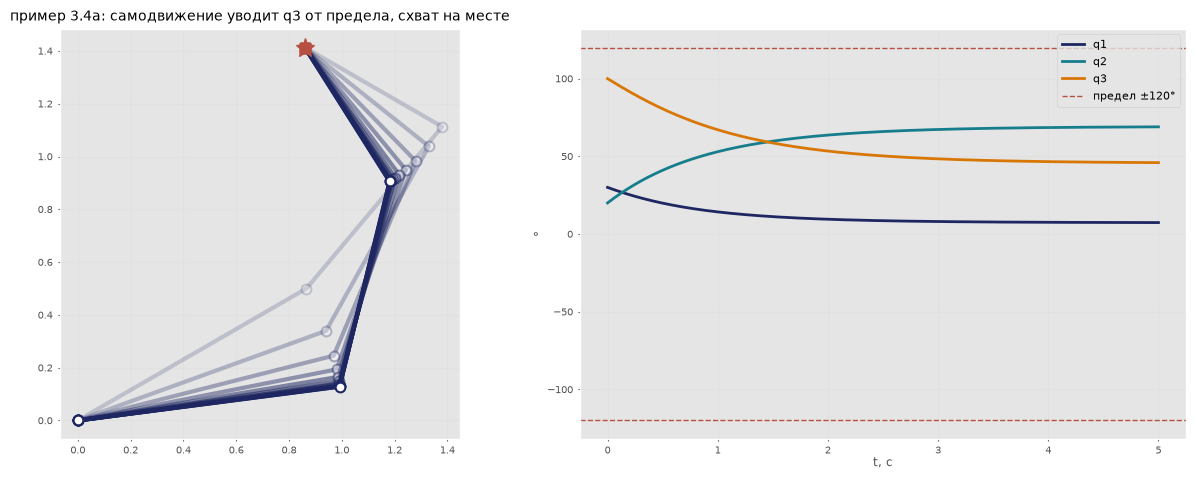

In [11]:
BREAK = False
l = np.array([1.0, 0.8, 0.6])
J2 = lambda q: jac_planar(q, l)[:2]                        # только положение схвата
pE = lambda q: fk_planar(q, l)[0][-1]
# (а) наименьшая норма
q = np.radians([20., 40., 30.]); J = J2(q); Jp = np.linalg.pinv(J); P = np.eye(3) - Jp @ J
v = np.array([0.2, -0.1]); qa = Jp @ v; qb = qa + P @ np.array([1., 0, 0])
ker = np.linalg.svd(J)[2][-1]; ker *= np.sign(ker[2])
print('(а) J⁺v =', qa.round(3), ' ‖·‖ = %.3f;  другое решение' % np.linalg.norm(qa), qb.round(3), ' ‖·‖ = %.3f;  J q̇ одинаково: %s' % (np.linalg.norm(qb), np.allclose(J @ qa, J @ qb)))
print('    базис ядра J:', ker.round(3))
# (б) самодвижение без коррекции и с коррекцией
def self_motion(q0, Tend, dt, K=0.0, xi=np.array([0., 0, 1])):
    qq = q0.copy(); p0 = pE(qq); dmax = 0.0
    for _ in range(int(round(Tend / dt))):
        J = J2(qq); Jp = np.linalg.pinv(J); qq = qq + dt * (Jp @ (K * (p0 - pE(qq))) + (np.eye(3) - Jp @ J) @ xi)
        dmax = max(dmax, np.linalg.norm(pE(qq) - p0))
    return qq, np.linalg.norm(pE(qq) - p0), dmax
for dt in (0.05, 0.005):
    print('(б) без коррекции, 3 с, Δt = %g с: дрейф схвата %.1e м' % (dt, self_motion(q, 3.0, dt)[1]))
for dt in (0.01, 0.001):
    qk, drk, dmk = self_motion(q, 3.0, dt, K=5.0)
    print('    с коррекцией K = 5 с⁻¹, Δt = %g с: наибольшее отклонение %.1e м, через 3 с %.1e м (не накапливается, ∝ Δt)' % (dt, dmk, drk))
print('    конфигурация через 3 с самодвижения:', np.degrees(qk).round(1), '°')

# (в) пример 3.4а
qlim = np.radians(120.); q0 = np.radians([30., 20., 100.])
grad = lambda qq: -2 * qq / qlim ** 2
J = J2(q0); P = np.eye(3) - np.linalg.pinv(J) @ J; Pxi = P @ grad(q0)
print('(в) ∇g =', grad(q0).round(3), '  Pξ (k = 1) =', Pxi.round(3), '  J·Pξ =', (J @ Pxi).round(12), '  ġ = %.3f' % (grad(q0) @ Pxi))
Kfb = 0.0 if BREAK else 5.0; k_, dt = 3.0, 0.01
qq = q0.copy(); p0 = pE(qq); hist = [qq.copy()]
for _ in range(500):
    J = J2(qq); Jp = np.linalg.pinv(J)
    qq = qq + dt * (Jp @ (Kfb * (p0 - pE(qq))) + (np.eye(3) - Jp @ J) @ (k_ * grad(qq))); hist.append(qq.copy())
hist = np.array(hist); drift = np.linalg.norm(pE(qq) - p0)
print('    через 5 с: q =', np.degrees(qq).round(1), '°, схват в', p0.round(3), 'м, отклонение %.1e м%s' % (drift, '  (СЛОМАНО: K = 0)' if BREAK else ''))
print('Сверка с конспектом:')
for i, s in enumerate(('−0,239', '−0,159', '−0,796')):
    check('∇g, компонента %d' % (i + 1), grad(q0)[i], s)
for i, s in enumerate(('−0,151', '0,317', '−0,253')):
    check('Pξ, компонента %d' % (i + 1), Pxi[i], s, 'рад/с')
check('ġ', grad(q0) @ Pxi, '0,187')
if not BREAK:
    for i, s in enumerate(('7,4', '69,0', '45,9')):
        check('q%d через 5 с' % (i + 1), np.degrees(qq[i]), s, '°')
    check('схват x', p0[0], '0,861', 'м'); check('схват y', p0[1], '1,413', 'м'); check_small('отклонение схвата', drift, '2e-8')

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.8))
for i in range(0, 501, 50):
    draw_arm2d(axs[0], hist[i], l, color=NAVY, lw=3, alpha=0.2 + 0.8 * i / 500)
axs[0].plot(*p0, '*', color=RED, ms=14); axs[0].set_aspect('equal'); axs[0].grid(alpha=.3)
axs[0].set_title('пример 3.4а: самодвижение уводит q3 от предела, схват на месте', fontsize=10)
tt = np.arange(501) * dt
for i, col in enumerate((NAVY, TEAL, AMB)):
    axs[1].plot(tt, np.degrees(hist[:, i]), color=col, lw=2, label='q%d' % (i + 1))
axs[1].axhline(120, color=RED, ls='--', lw=1, label='предел ±120°'); axs[1].axhline(-120, color=RED, ls='--', lw=1)
axs[1].set_xlabel('t, с'); axs[1].set_ylabel('°'); axs[1].grid(alpha=.3); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Демонстрация 9. Сфера, эллипс, взвешенный эллипс и многоугольник (§ 3.8, примеры 3.5 и 3.6)

Двухзвенник $l_1=l_2=1$ м, пределы $C_1=0{,}1$ и $C_2=0{,}5$ рад/с, $C=\sqrt{C_1^2+C_2^2}\approx0{,}51$ рад/с. Сначала таблица радиусов сфер $\sigma_{\max}C$ примера 3.5 и книжные значения, полученные умножением $C$ на $\sigma_{\max}^2$ (пропущенный корень). Затем точка $\mathbf q=(0,\pi/2)$ примера 3.6:

* сфера радиуса $\sigma_{\max}C$ (3.184) и эллипс — образ круга $\lVert\dot{\mathbf q}\rVert\le C$ с полуосями $\sigma_iC$ вдоль $\hat{\mathbf u}_i$;
* многоугольник — образ прямоугольника $\lvert\dot q_i\rvert\le C_i$: гарантированные значения;
* взвешенный эллипс — образ единичного круга при отображении $J_v\operatorname{diag}(C_1,C_2)$: вписан в многоугольник, а увеличенный в $\sqrt2$ раз описан вокруг него;
* луч вдоль большой оси невзвешенного эллипса: эллипс обещает 0,83 м/с, а многоугольник допускает лишь 0,19 м/с.

**Сломай и посмотри** (`BREAK = True`): пределы делаются одинаковыми, $C_1=C_2=0{,}3$ рад/с. Тогда невзвешенный и взвешенный эллипсы совпадают с точностью до множителя, и большая ось эллипса снова указывает быстрое направление — вывод «эллипс показывает быстрое направление» верен только при равных пределах.

пример 3.5: C = 0.510 рад/с
  q2, °   σ_max   радиус σ_max·C   книжное C·σ_max²
   180   1.000            0.510              0.510
   135   1.073            0.547              0.587
    90   1.618            0.825              1.335
    45   2.073            1.057              2.191
     0   2.236            1.140              2.550
  у вытянутой руки точный максимум |v| = 2C1 + C2 = 0.70 м/с
пример 3.6: σ = [1.618 0.618]  сфера 0.825, полуоси эллипса 0.825 и 0.315, большая ось -31.7°
  вершины многоугольника: [[-0.6, 0.1], [-0.4, -0.1], [0.6, -0.1], [0.4, 0.1]]  стороны [0.283, 1.0]  расстояния [0.412 0.608]
  дальняя вершина [ 0.6 -0.1] под -9.5°; вдоль y: многоугольник 0.100, эллипс 0.361 м/с; вдоль x: 0.500 и 0.510 м/с
  вдоль большой оси эллипса: q̇ ∝ [0.85 0.53] , многоугольник 0.190, эллипс 0.825 (в 4.3 раза больше)
  отношение «эллипс / многоугольник» по направлениям: от 1.00 до 5.10
  взвешенный эллипс: полуоси 0.510 и 0.098, большая ось -2.3°; сфера / максимум = 1.36, сфера /

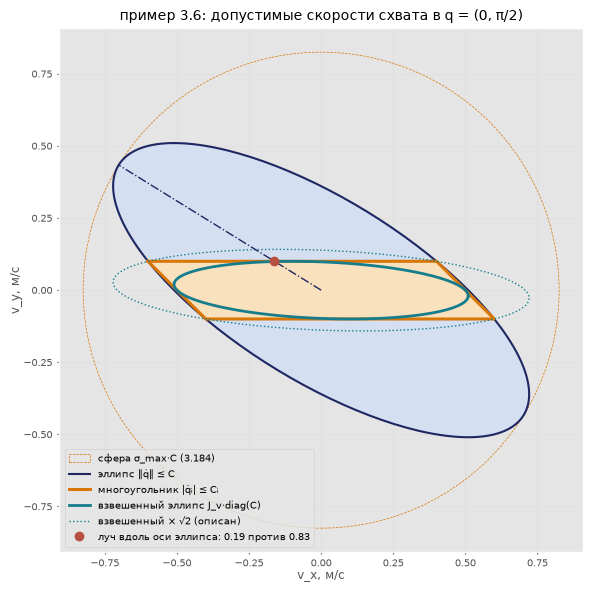

In [12]:
BREAK = False
l = (1.0, 1.0); Cv = np.array([0.3, 0.3]) if BREAK else np.array([0.1, 0.5]); C = np.linalg.norm(Cv)
print('пример 3.5: C = %.3f рад/с' % C)
print('  q2, °   σ_max   радиус σ_max·C   книжное C·σ_max²')
lect = {180: '0,51', 135: '0,55', 90: '0,83', 45: '1,06', 0: '1,14'}; rads = {}
for d in lect:
    s = svals(jac2r((0.0, np.radians(d)), l)); rads[d] = s[0] * C
    print('  %4d   %5.3f   %14.3f   %16.3f' % (d, s[0], s[0] * C, C * s[0] ** 2))
print('  у вытянутой руки точный максимум |v| = 2C1 + C2 = %.2f м/с' % (2 * Cv[0] + Cv[1]))
J = jac2r((0.0, np.pi / 2), l); U, S, Vt = np.linalg.svd(J)
axis = np.degrees(np.arctan2(U[1, 0], U[0, 0])); axis = (axis + 90) % 180 - 90
poly = polygon_image(J, Cv); dist = np.linalg.norm(poly, axis=1)
sides = sorted({round(np.linalg.norm(poly[i] - poly[i - 1]), 3) for i in range(len(poly))})
def r_poly(n):  return np.min(Cv / np.abs(np.linalg.solve(J, n)))
def r_ell(n):   return C / np.linalg.norm(np.linalg.solve(J, n))
u1 = U[:, 0]; qdir = np.linalg.solve(J, u1); qdir /= np.linalg.norm(qdir) * np.sign(qdir[0])
Uw, Sw, _ = np.linalg.svd(J @ np.diag(Cv)); axis_w = np.degrees(np.arctan2(Uw[1, 0], Uw[0, 0])); axis_w = (axis_w + 90) % 180 - 90
far = poly[np.argmax(dist)]; far = far if far[0] > 0 else -far
phis = np.radians(np.linspace(0, 180, 3601)); ratio = [r_ell(np.array([np.cos(p), np.sin(p)])) / r_poly(np.array([np.cos(p), np.sin(p)])) for p in phis]
print('пример 3.6: σ =', S.round(3), ' сфера %.3f, полуоси эллипса %.3f и %.3f, большая ось %.1f°' % (S[0] * C, S[0] * C, S[1] * C, axis))
print('  вершины многоугольника:', poly.round(2).tolist(), ' стороны', sides, ' расстояния', np.unique(dist.round(3)))
print('  дальняя вершина', far.round(2), 'под %.1f°; вдоль y: многоугольник %.3f, эллипс %.3f м/с; вдоль x: %.3f и %.3f м/с' % (
    np.degrees(np.arctan2(far[1], far[0])), r_poly(np.array([0, 1.])), r_ell(np.array([0, 1.])), r_poly(np.array([1., 0])), r_ell(np.array([1., 0]))))
print('  вдоль большой оси эллипса: q̇ ∝', qdir.round(2), ', многоугольник %.3f, эллипс %.3f (в %.1f раза больше)' % (r_poly(u1), r_ell(u1), r_ell(u1) / r_poly(u1)))
print('  отношение «эллипс / многоугольник» по направлениям: от %.2f до %.2f' % (min(ratio), max(ratio)))
print('  взвешенный эллипс: полуоси %.3f и %.3f, большая ось %.1f°; сфера / максимум = %.2f, сфера / ближняя вершина = %.2f' % (
    Sw[0], Sw[1], axis_w, S[0] * C / dist.max(), S[0] * C / dist.min()))
if not BREAK:
    print('Сверка с конспектом:')
    for d, s in lect.items():
        check('радиус сферы при q2 = %d°' % d, rads[d], s, 'м/с')
    check('точный максимум у вытянутой руки', 2 * Cv[0] + Cv[1], '0,70', 'м/с')
    check('σ_max', S[0], '1,618'); check('σ_min', S[1], '0,618'); check('радиус сферы', S[0] * C, '0,83', 'м/с')
    check('малая полуось эллипса', S[1] * C, '0,32', 'м/с'); check('наклон большой оси', axis, '−32', '°')
    check('сторона параллелограмма (короткая)', sides[0], '0,28'); check('сторона параллелограмма (длинная)', sides[-1], '1,0')
    check('дальняя вершина', dist.max(), '0,61', 'м/с'); check('ближняя вершина', dist.min(), '0,41', 'м/с')
    check('направление на дальнюю вершину', np.degrees(np.arctan2(far[1], far[0])), '−9,5', '°')
    check('вдоль оси y (многоугольник)', r_poly(np.array([0, 1.])), '0,1', 'м/с'); check('вдоль оси y (эллипс)', r_ell(np.array([0, 1.])), '0,36', 'м/с')
    check('вдоль оси x (многоугольник)', r_poly(np.array([1., 0])), '0,5', 'м/с')
    check('q̇ вдоль большой оси, первая компонента', qdir[0], '0,85'); check('q̇ вдоль большой оси, вторая компонента', qdir[1], '0,53')
    check('многоугольник вдоль большой оси', r_poly(u1), '0,19', 'м/с'); check('эллипс вдоль большой оси', r_ell(u1), '0,83', 'м/с')
    check('завышение вдоль большой оси', r_ell(u1) / r_poly(u1), '4,3', 'раза'); check('min отношения', min(ratio), '1,0'); check('max отношения', max(ratio), '5,1')
    check('взвешенный эллипс, большая полуось', Sw[0], '0,51', 'м/с'); check('взвешенный эллипс, малая полуось', Sw[1], '0,098', 'м/с')
    check('взвешенный эллипс, наклон оси', axis_w, '−2,3', '°'); check('сфера / максимум', S[0] * C / dist.max(), '1,4', 'раза')
    check('сфера / ближняя вершина', S[0] * C / dist.min(), '2', 'раза')

ell = ellipse_image(J, C); t = np.linspace(0, 2 * np.pi, 300)
ellw = (Uw[:, :2] * Sw) @ np.vstack([np.cos(t), np.sin(t)])
fig, ax = plt.subplots(figsize=(6.8, 6.8))
ax.add_patch(plt.Circle((0, 0), S[0] * C, fill=False, ls='--', color=AMB, label='сфера σ_max·C (3.184)'))
ax.fill(ell[:, 0], ell[:, 1], color=ICE, alpha=.6); ax.plot(ell[:, 0], ell[:, 1], color=NAVY, lw=1.5, label='эллипс ‖q̇‖ ≤ C')
ax.fill(poly[:, 0], poly[:, 1], color='#FFE2B8', alpha=.9); ax.plot(np.r_[poly[:, 0], poly[0, 0]], np.r_[poly[:, 1], poly[0, 1]], color=AMB, lw=2.2, label='многоугольник |q̇ᵢ| ≤ Cᵢ')
ax.plot(ellw[0], ellw[1], color=TEAL, lw=2, label='взвешенный эллипс J_v·diag(C)')
ax.plot(np.sqrt(2) * ellw[0], np.sqrt(2) * ellw[1], color=TEAL, lw=1, ls=':', label='взвешенный × √2 (описан)')
ax.plot([0, r_ell(u1) * u1[0]], [0, r_ell(u1) * u1[1]], color=NAVY, lw=1, ls='-.'); ax.plot(*(r_poly(u1) * u1), 'o', color=RED, ms=6, label='луч вдоль оси эллипса: %.2f против %.2f' % (r_poly(u1), r_ell(u1)))
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(loc='lower left', fontsize=7.5); ax.set_xlabel('v_x, м/с'); ax.set_ylabel('v_y, м/с')
ax.set_title('пример 3.6: допустимые скорости схвата в q = (0, π/2)' + ('  [СЛОМАНО: C₁ = C₂]' if BREAK else ''), fontsize=10); plt.show()

## Демонстрация 10. Меры качества конфигурации (§ 3.4, § 3.8)

Три мировые меры: мера Йошикавы $w=\sqrt{\det(JJ^{\mathrm T})}=\sigma_1\cdots\sigma_m$, число обусловленности $\kappa(J)=\sigma_{\max}/\sigma_{\min}$ и само $\sigma_{\min}$. У двухзвенника $l_1=l_2=1$ м меры $w$ и $\kappa(J)$ выбирают разные «лучшие» позы; изотропная поза появляется только при $l_2/l_1=1/\sqrt2$.

У UR5e полная матрица $6\times6$ смешивает безразмерные строки угловой скорости со строками длины, поэтому $\kappa(J)$ и $\sigma_{\min}$ зависят от единиц. Правильно — анализировать блоки отдельно или нормировать линейный блок характерной длиной (вылетом 0,85 м). Здесь же — оценка точности из § 3.4: $\lVert\delta\mathbf p\rVert\le\sigma_{\max}(J_v)\lVert\delta\mathbf q\rVert$ при ошибке $0{,}01^\circ$ в каждом сочленении.

**Сломай и посмотри** (`BREAK = True`): сравниваются две конфигурации UR5e по $\sigma_{\min}$ полной матрицы в метрах и в миллиметрах: A — конфигурация раздела 3.3, B — та же, но с $q_3=0{,}2$ и $q_5=1{,}5$ рад (локоть почти вытянут). Выводы о том, какая «ближе к особенности», противоположны: в метрах это B, в миллиметрах — A, хотя к локтевой особенности на самом деле близка B.

2R: max w = 1.000 при q2 = 90.0° (σ = 1.618; 0.618, κ(J) = 2.618);  min κ(J) = 1.618 при q2 = 131.8°
2R с l2/l1 = 1/√2 при q2 = 135°: σ = [0.7071 0.7071]  κ(J) = 1.0000
UR5e, конфигурация раздела 3.3: κ(J) = 10.9 в метрах, 1872 в миллиметрах; σ_min = 0.186 и 0.461
   κ(J_v) = 3.51, κ(J_ω) = 2.36, после деления линейного блока на 0.85 м κ(J_n) = 9.6
точность: σ_max(J_v) = 0.864 м, оценка сверху 0.37 мм, наихудший перебор знаков 0.27 мм
Сверка с конспектом:
  совпадает   2R: q2 с максимальным w: расчёт 90.0, конспект 90 °
  совпадает   2R: κ при 90°: расчёт 2.6180, конспект 2,618 
  совпадает   2R: минимальное κ: расчёт 1.6180, конспект 1,618 
  совпадает   2R: q2 с минимальным κ: расчёт 131.81, конспект 131,8 °
  совпадает   изотропная поза: σ: расчёт 0.7071, конспект 0,707 ·l1
  совпадает   изотропная поза: κ: расчёт 1.000, конспект 1,00 
  совпадает   UR5e κ(J), м: расчёт 10.86, конспект 10,9 
  совпадает   UR5e κ(J), мм: расчёт 1872.4, конспект 1872 
  совпадает   UR5e σ_min, м: расч

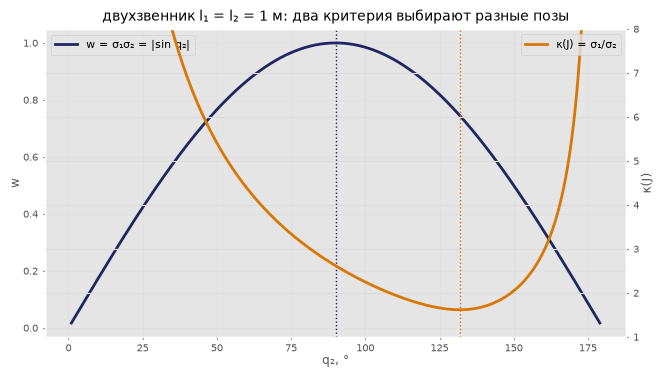

In [13]:
BREAK = False
from itertools import product
l = (1.0, 1.0); q2s = np.radians(np.linspace(1, 179, 17801))
sv = np.array([svals(jac2r((0.0, t), l)) for t in q2s]); w2, k2 = sv[:, 0] * sv[:, 1], sv[:, 0] / sv[:, 1]
iw, ik = np.argmax(w2), np.argmin(k2)
print('2R: max w = %.3f при q2 = %.1f° (σ = %.3f; %.3f, κ(J) = %.3f);  min κ(J) = %.3f при q2 = %.1f°' % (w2[iw], np.degrees(q2s[iw]), *sv[iw], k2[iw], k2[ik], np.degrees(q2s[ik])))
s_iso = svals(jac2r((0.0, np.radians(135)), (1.0, 1 / np.sqrt(2))))
print('2R с l2/l1 = 1/√2 при q2 = 135°: σ =', s_iso.round(4), ' κ(J) = %.4f' % (s_iso[0] / s_iso[1]))

ur = make_ur5e(); ur.forward(Q33.copy()); J = ur.jacobian_book()
Jmm = J.copy(); Jmm[3:] *= 1000; Jn = J.copy(); Jn[3:] /= ur.reach
print('UR5e, конфигурация раздела 3.3: κ(J) = %.1f в метрах, %.0f в миллиметрах; σ_min = %.3f и %.3f' % (np.linalg.cond(J), np.linalg.cond(Jmm), svals(J)[-1], svals(Jmm)[-1]))
print('   κ(J_v) = %.2f, κ(J_ω) = %.2f, после деления линейного блока на %.2f м κ(J_n) = %.1f' % (np.linalg.cond(J[3:]), np.linalg.cond(J[:3]), ur.reach, np.linalg.cond(Jn)))
dq = np.radians(0.01) * np.ones(6); smax_v = svals(J[3:])[0]
worst = max(np.linalg.norm(J[3:] @ (np.array(sg) * dq)) for sg in product((-1, 1), repeat=6))
print('точность: σ_max(J_v) = %.3f м, оценка сверху %.2f мм, наихудший перебор знаков %.2f мм' % (smax_v, 1e3 * smax_v * np.linalg.norm(dq), 1e3 * worst))
if BREAK:
    qB = Q33.copy(); qB[2] = 0.2; qB[4] = 1.5                     # B: локоть почти вытянут (q3 = 0,2 рад)
    ur.forward(qB.copy()); JB = ur.jacobian_book(); JBmm = JB.copy(); JBmm[3:] *= 1000
    sA, sB, sAmm, sBmm = svals(J)[-1], svals(JB)[-1], svals(Jmm)[-1], svals(JBmm)[-1]
    print('СЛОМАНО: σ_min в метрах: A = %.3f, B = %.3f -> ближе к особенности %s' % (sA, sB, 'B' if sB < sA else 'A'))
    print('         σ_min в миллиметрах: A = %.3f, B = %.3f -> ближе к особенности %s' % (sAmm, sBmm, 'B' if sBmm < sAmm else 'A'))
    print('         на самом деле B близка к локтевой особенности: |s3| = %.2f; σ_min(J_v) у A и B: %.3f и %.3f м' % (abs(np.sin(qB[2])), svals(J[3:])[-1], svals(JB[3:])[-1]))
    ur.forward(Q33.copy())
print('Сверка с конспектом:')
check('2R: q2 с максимальным w', np.degrees(q2s[iw]), '90', '°'); check('2R: κ при 90°', k2[iw], '2,618')
check('2R: минимальное κ', k2[ik], '1,618'); check('2R: q2 с минимальным κ', np.degrees(q2s[ik]), '131,8', '°')
check('изотропная поза: σ', s_iso[0], '0,707', '·l1'); check('изотропная поза: κ', s_iso[0] / s_iso[1], '1,00')
check('UR5e κ(J), м', np.linalg.cond(J), '10,9'); check('UR5e κ(J), мм', np.linalg.cond(Jmm), '1872')
check('UR5e σ_min, м', svals(J)[-1], '0,186'); check('UR5e σ_min, мм', svals(Jmm)[-1], '0,461')
check('UR5e κ(J_v)', np.linalg.cond(J[3:]), '3,51'); check('UR5e κ после нормировки 0,85 м', np.linalg.cond(Jn), '9,6')
check('σ_max(J_v)', smax_v, '0,864', 'м'); check('оценка сверху', 1e3 * smax_v * np.linalg.norm(dq), '0,37', 'мм'); check('наихудший перебор', 1e3 * worst, '0,27', 'мм')

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(np.degrees(q2s), w2, color=NAVY, lw=2, label='w = σ₁σ₂ = |sin q₂|')
ax2 = ax.twinx(); ax2.plot(np.degrees(q2s), k2, color=AMB, lw=2, label='κ(J) = σ₁/σ₂'); ax2.set_ylim(1, 8)
ax.axvline(90, color=NAVY, ls=':', lw=1); ax2.axvline(np.degrees(q2s[ik]), color=AMB, ls=':', lw=1)
ax.set_xlabel('q₂, °'); ax.set_ylabel('w'); ax2.set_ylabel('κ(J)'); ax.grid(alpha=.3)
ax.legend(loc='upper left', fontsize=8); ax2.legend(loc='upper right', fontsize=8)
ax.set_title('двухзвенник l₁ = l₂ = 1 м: два критерия выбирают разные позы', fontsize=10); plt.show()

## Демонстрация 11. Мобильность и манипулятивность (§ 3.9)

Мобильность двухзвенника — площадь многоугольника допустимых скоростей: $\mathcal M=\lvert\det J_v\rvert\cdot4C_1C_2=0{,}2\lvert\sin q_2\rvert$ при $l_1=l_2=1$ м, $C_1=0{,}1$, $C_2=0{,}5$ рад/с. Она зависит только от расстояния до основания; максимум 0,2 м²/с² — на окружности радиуса $\sqrt2$ м. Мобильность по направлению $\mathbf n$: для многоугольника $r=\min_iC_i/\lvert(J_v^{-1}\mathbf n)_i\rvert$ (ограничивает то сочленение, которое первым выходит на предел), для эллипса $r=C/\lVert J_v^{-1}\mathbf n\rVert$. Справа — карта меры $w=\lvert\det J\rvert$ UR5e в плоскости $(q_2,q_3)$ при $q_4=-1{,}0$, $q_5=0{,}8$ рад; поверх нанесены нули множителей формулы примера 3.3а: $s_3=0$ (локоть) и $a_2c_2+a_3c_{23}+d_5s_{234}=0$ (плечо).

**Сломай и посмотри** (`BREAK = True`): пределы скоростей меняются местами ($C_1=0{,}5$, $C_2=0{,}1$). Карта интегральной мобильности не меняется вовсе (она зависит только от произведения $C_1C_2$), а полярная диаграмма мобильности по направлению поворачивается — интегральная мера не говорит, куда можно двигаться быстро.

2R: max 𝓜 = 0.200 м²/с² на радиусе 1.414 м (√2 = 1.414);  max|𝓜 − 0,2|sin q2|| = 1.0e-15
q = (0, π/2): мобильность вдоль y: многоугольник 0.100, эллипс 0.361 м/с; вдоль x: 0.500 и 0.510 м/с
Сверка с конспектом:
  совпадает   max 𝓜: расчёт 0.20, конспект 0,2 м²/с²
  совпадает   радиус максимума (в конспекте √2 м): расчёт 1.414, конспект 1,41 м
  совпадает   мобильность вдоль y: расчёт 0.10, конспект 0,1 м/с
  совпадает   эллипс вдоль y: расчёт 0.361, конспект 0,36 м/с
  совпадает   мобильность вдоль x: расчёт 0.50, конспект 0,5 м/с


UR5e: max|w численно − |формула 3.3а|| по карте = 9.7e-17


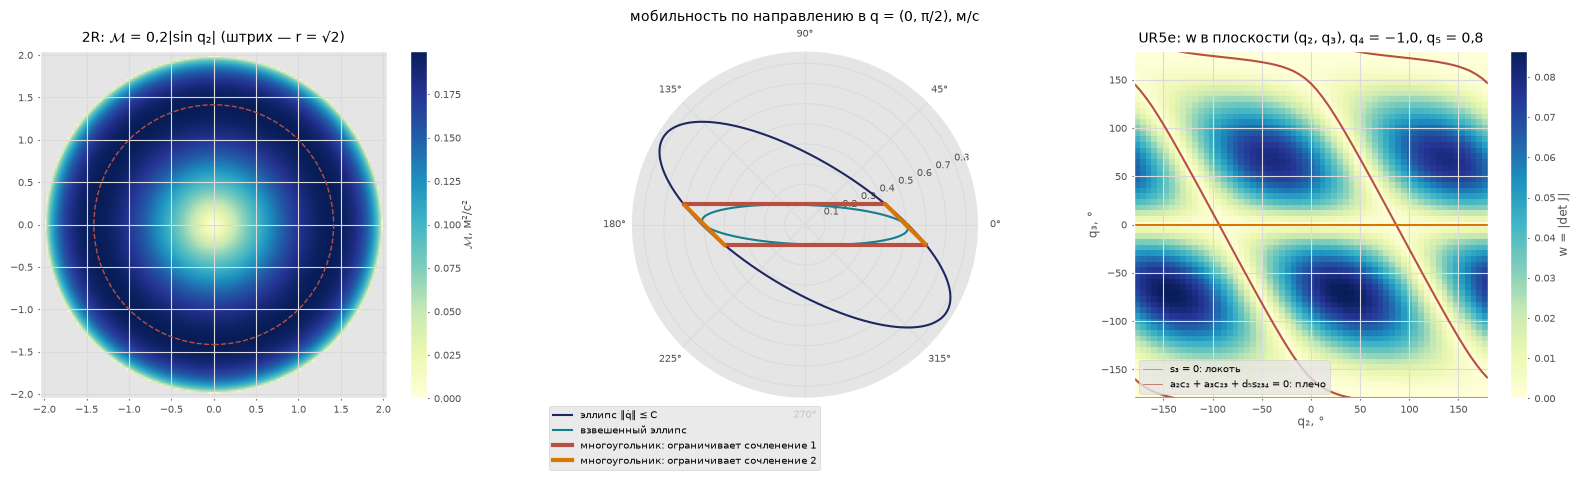

In [14]:
BREAK = False
l = (1.0, 1.0); Cv = np.array([0.5, 0.1]) if BREAK else np.array([0.1, 0.5]); C = np.linalg.norm(Cv)
N = 161; xs = np.linspace(-2.05, 2.05, N); X, Y = np.meshgrid(xs, xs); Mob = np.full_like(X, np.nan)
for i in range(N):
    for j in range(N):
        sol = ik2r(X[i, j], Y[i, j], l)
        if sol:
            Mob[i, j] = abs(np.linalg.det(jac2r(sol[0], l))) * 4 * Cv[0] * Cv[1]
rr = np.hypot(X, Y); im = np.nanargmax(Mob)
print('2R: max 𝓜 = %.3f м²/с² на радиусе %.3f м (√2 = %.3f);  max|𝓜 − 0,2|sin q2|| = %.1e' % (
    np.nanmax(Mob), rr.ravel()[im], np.sqrt(2), np.nanmax(np.abs(Mob - 4 * Cv[0] * Cv[1] * np.sqrt(np.clip(1 - ((rr ** 2 - 2) / 2) ** 2, 0, 1))))))
J = jac2r((0.0, np.pi / 2), l); phis = np.radians(np.linspace(0, 360, 721))
rp = np.array([np.min(Cv / np.abs(np.linalg.solve(J, [np.cos(p), np.sin(p)]))) for p in phis])
re = np.array([C / np.linalg.norm(np.linalg.solve(J, [np.cos(p), np.sin(p)])) for p in phis])
rw = np.array([1 / np.linalg.norm(np.linalg.solve(J, [np.cos(p), np.sin(p)]) / Cv) for p in phis])
lim_joint = np.array([np.argmin(Cv / np.abs(np.linalg.solve(J, [np.cos(p), np.sin(p)]))) for p in phis])
print('q = (0, π/2): мобильность вдоль y: многоугольник %.3f, эллипс %.3f м/с; вдоль x: %.3f и %.3f м/с' % (rp[180], re[180], rp[0], re[0]))
if not BREAK:
    print('Сверка с конспектом:')
    check('max 𝓜', np.nanmax(Mob), '0,2', 'м²/с²'); check('радиус максимума (в конспекте √2 м)', rr.ravel()[im], '1,41', 'м')
    check('мобильность вдоль y', rp[180], '0,1', 'м/с'); check('эллипс вдоль y', re[180], '0,36', 'м/с'); check('мобильность вдоль x', rp[0], '0,5', 'м/с')

ur = make_ur5e(); g = np.linspace(-np.pi, np.pi, 61); Wd = np.zeros((len(g), len(g))); Wf = np.zeros_like(Wd)
a2, a3, d5 = UR5E_DH[1, 1], UR5E_DH[2, 1], UR5E_DH[4, 0]; q4c, q5c = -1.0, 0.8
for i, q3 in enumerate(g):
    for j, q2 in enumerate(g):
        ur.forward(np.array([0.0, q2, q3, q4c, q5c, 0.0])); Wd[i, j] = abs(np.linalg.det(ur.jacobian_book()))
        Wf[i, j] = abs(a2 * a3 * np.sin(q3) * np.sin(q5c) * (a2 * np.cos(q2) + a3 * np.cos(q2 + q3) + d5 * np.sin(q2 + q3 + q4c)))
print('UR5e: max|w численно − |формула 3.3а|| по карте = %.1e' % np.abs(Wd - Wf).max())

fig = plt.figure(figsize=(16, 4.8))
ax = fig.add_subplot(131)
imh = ax.imshow(Mob, extent=[xs[0], xs[-1], xs[0], xs[-1]], origin='lower', cmap='YlGnBu'); plt.colorbar(imh, ax=ax, label=r'$\mathcal{M}$, м²/с²')
ax.add_patch(plt.Circle((0, 0), np.sqrt(2), fill=False, color=RED, ls='--', lw=1)); ax.set_aspect('equal')
ax.set_title(r'2R: $\mathcal{M}$ = 0,2|sin q₂| (штрих — r = √2)', fontsize=10)
ax = fig.add_subplot(132, projection='polar')
ax.plot(phis, re, color=NAVY, lw=1.5, label='эллипс ‖q̇‖ ≤ C'); ax.plot(phis, rw, color=TEAL, lw=1.5, label='взвешенный эллипс')
for jn, col in ((0, RED), (1, AMB)):
    m = lim_joint == jn; ax.plot(np.where(m, phis, np.nan), np.where(m, rp, np.nan), color=col, lw=3, label='многоугольник: ограничивает сочленение %d' % (jn + 1))
ax.legend(fontsize=7, loc='lower left', bbox_to_anchor=(-0.25, -0.22)); ax.set_title('мобильность по направлению в q = (0, π/2), м/с', fontsize=10)
ax = fig.add_subplot(133)
imw = ax.imshow(Wd, extent=[-180, 180, -180, 180], origin='lower', cmap='YlGnBu', aspect='auto'); plt.colorbar(imw, ax=ax, label='w = |det J|')
G2, G3 = np.meshgrid(np.degrees(g), np.degrees(g))
ax.contour(G2, G3, a2 * np.cos(np.radians(G2)) + a3 * np.cos(np.radians(G2 + G3)) + d5 * np.sin(np.radians(G2 + G3) + q4c), levels=[0], colors=[RED], linewidths=1.5)
for v3 in (-180, 0, 180):
    ax.axhline(v3, color=AMB, lw=1.5)
ax.plot([], [], color=AMB, label='s₃ = 0: локоть'); ax.plot([], [], color=RED, label='a₂c₂ + a₃c₂₃ + d₅s₂₃₄ = 0: плечо')
ax.set_xlabel('q₂, °'); ax.set_ylabel('q₃, °'); ax.legend(fontsize=7, loc='lower left')
ax.set_title('UR5e: w в плоскости (q₂, q₃), q₄ = −1,0, q₅ = 0,8', fontsize=10)
plt.tight_layout(); plt.show()

## Демонстрация 12. Двойственность скоростей и сил (§ 3.10)

Из равенства мощностей $\boldsymbol\tau^{\mathrm T}\dot{\mathbf q}=\mathbf F^{\mathrm T}\boldsymbol{\mathcal V}$ следует $\boldsymbol\tau=J^{\mathrm T}\mathbf F$, где силовой винт $\mathbf F=(\mathbf m;\mathbf f)$ записан в том же порядке, что $(\boldsymbol\omega;\mathbf v)$. У двухзвенника $l_1=l_2=1$ м при $q_2=90^\circ$ эллипс скоростей ($\lVert\dot{\mathbf q}\rVert\le1$) и эллипс сил ($\lVert\boldsymbol\tau\rVert\le1$) имеют общие оси $\hat{\mathbf u}_i$, а полуоси $\sigma_i$ и $1/\sigma_i$ — в обратном порядке. У вытянутой руки сила вдоль руки не требует моментов.

Дополнительно на UR5e проверим, что равенство мощностей выполняется именно с геометрическим якобианом: работа силового винта на малом перемещении схвата $(\delta\boldsymbol\varphi;\delta\mathbf p)$ совпадает с $(J^{\mathrm T}\mathbf F)^{\mathrm T}\delta\mathbf q$, а с аналитическим якобианом (углы ZYZ) — нет.

**Сломай и посмотри** (`BREAK = True`): двухзвенник ставится в вытянутую позу $q_2=0$ — эллипс скоростей вырождается в отрезок, а эллипс сил становится бесконечным вдоль руки.

q2 = 90°: σ = [1.618 0.618], оси эллипсов (столбцы U):
 [[-0.8507  0.5257]
 [ 0.5257  0.8507]]
эллипс скоростей: полуоси 1.618 и 0.618;  эллипс сил: полуоси 0.618 и 1.618 вдоль тех же осей; ‖Jᵀf‖ на концах = [1. 1.]
Сверка с конспектом:
  совпадает   полуось скоростей по u1: расчёт 1.6180, конспект 1,618 
  совпадает   полуось скоростей по u2: расчёт 0.6180, конспект 0,618 
  совпадает   полуось сил по u1: расчёт 0.6180, конспект 0,618 
  совпадает   полуось сил по u2: расчёт 1.6180, конспект 1,618 
вытянутая рука q = (0,3; 0): сила вдоль руки f = [0.955 0.296]  τ = Jᵀf = [0. 0.]
равенство мощностей τᵀq̇ = fᵀv: -0.865257 = -0.865257
UR5e: работа F на перемещении схвата 1.5595e-05;  (JᵀF)ᵀδq = 1.5595e-05;  (J_AᵀF)ᵀδq = 1.6366e-05 (аналитический якобиан не годится)


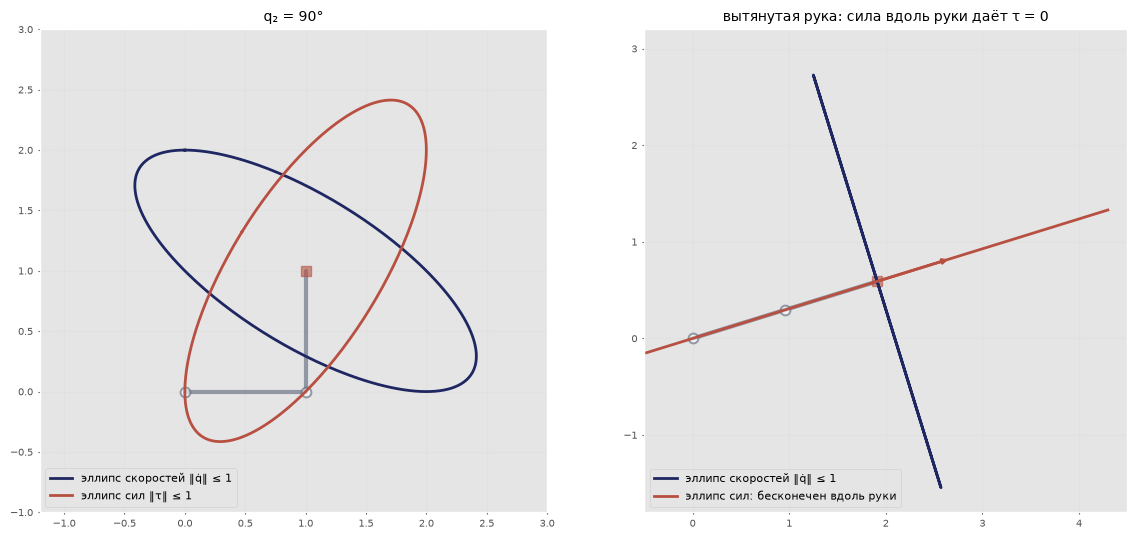

In [15]:
BREAK = False
l = (1.0, 1.0); q = (0.0, 0.0 if BREAK else np.pi / 2)
J = jac2r(q, l); U, S, Vt = np.linalg.svd(J)
print('q2 = %d°: σ = %s, оси эллипсов (столбцы U):\n' % (np.degrees(q[1]), S.round(3)), U.round(4))
if not BREAK:
    Fs = np.array([U[:, i] / S[i] for i in range(2)])                       # полуоси эллипса сил
    print('эллипс скоростей: полуоси %.3f и %.3f;  эллипс сил: полуоси %.3f и %.3f вдоль тех же осей; ‖Jᵀf‖ на концах =' % (S[0], S[1], 1 / S[0], 1 / S[1]), np.linalg.norm(J.T @ Fs.T, axis=0).round(6))
    print('Сверка с конспектом:')
    check('полуось скоростей по u1', S[0], '1,618'); check('полуось скоростей по u2', S[1], '0,618')
    check('полуось сил по u1', 1 / S[0], '0,618'); check('полуось сил по u2', 1 / S[1], '1,618')
qs_ = (0.3, 0.0); Js = jac2r(qs_, l); f_arm = np.array([np.cos(0.3), np.sin(0.3)])
print('вытянутая рука q = (0,3; 0): сила вдоль руки f =', f_arm.round(3), ' τ = Jᵀf =', (Js.T @ f_arm).round(15))
rng = np.random.default_rng(5); qd_r, f_r = rng.normal(size=2), rng.normal(size=2)
print('равенство мощностей τᵀq̇ = fᵀv: %.6f = %.6f' % ((J.T @ f_r) @ qd_r, f_r @ (J @ qd_r)))

ur = make_ur5e(); q6 = Q33.copy(); T0 = ur.forward(q6.copy()); Jg = ur.jacobian_book()
F = np.r_[rng.normal(size=3), rng.normal(size=3) * 10]                     # (m; f): Н·м и Н
dq = 1e-6 * rng.normal(size=6); T1 = ur.forward((q6 + dq).copy())
work = F @ np.r_[so3_log(T1.r_3_3 @ T0.r_3_3.T), T1.t_3_1.ravel() - T0.t_3_1.ravel()]
ph, th, _ = T0.euler_zyz
Winv = np.array([[0, -np.sin(ph), np.cos(ph) * np.sin(th)], [0, np.cos(ph), np.sin(ph) * np.sin(th)], [1, 0, np.cos(th)]])
JA = blk(np.linalg.inv(Winv), E3) @ Jg; ur.forward(q6.copy())
print('UR5e: работа F на перемещении схвата %.4e;  (JᵀF)ᵀδq = %.4e;  (J_AᵀF)ᵀδq = %.4e (аналитический якобиан не годится)' % (work, (Jg.T @ F) @ dq, (JA.T @ F) @ dq))

t = np.linspace(0, 2 * np.pi, 300); circ = np.vstack([np.cos(t), np.sin(t)])
fig, axs = plt.subplots(1, 2, figsize=(12, 5.4))
for ax, qq, ttl in ((axs[0], q, 'q₂ = %d°' % np.degrees(q[1])), (axs[1], qs_, 'вытянутая рука: сила вдоль руки даёт τ = 0')):
    Jq = jac2r(qq, l); Uq, Sq, _ = np.linalg.svd(Jq); pts = draw_arm2d(ax, qq, l, color=GREY, lw=3, alpha=.6)
    ve = Jq @ circ; ax.plot(pts[-1, 0] + ve[0], pts[-1, 1] + ve[1], color=NAVY, lw=2, label='эллипс скоростей ‖q̇‖ ≤ 1')
    if Sq[-1] > 1e-9:
        fe = (Uq / Sq) @ circ; ax.plot(pts[-1, 0] + fe[0], pts[-1, 1] + fe[1], color=RED, lw=2, label='эллипс сил ‖τ‖ ≤ 1')
    else:
        d = Uq[:, 1]; ax.plot(pts[-1, 0] + 2.5 * np.array([-d[0], d[0]]), pts[-1, 1] + 2.5 * np.array([-d[1], d[1]]), color=RED, lw=2, label='эллипс сил: бесконечен вдоль руки')
        ax.annotate('', pts[-1] + 0.8 * d, pts[-1], arrowprops=dict(arrowstyle='-|>', color=RED, lw=2))
    ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8, loc='lower left'); ax.set_title(ttl, fontsize=10)
axs[0].set_xlim(-1.2, 3.0); axs[0].set_ylim(-1.0, 3.0); axs[1].set_xlim(-0.5, 4.5); axs[1].set_ylim(-1.8, 3.2)
plt.tight_layout(); plt.show()

## Демонстрация 13. Приемистость и интерактивная модель (§ 3.11)

При разгоне из состояния покоя $\dot{\mathbf q}=0$, слагаемое $\dot J_v\dot{\mathbf q}$ исчезает, и $\dot{\mathbf v}_N=J_v\ddot{\mathbf q}$ — та же линейная структура, что у скоростей. Ограничения $\lvert\ddot q_i\rvert\le b_i$ дают многоугольник допустимых ускорений $\Gamma_a$. Возьмём $b=(1;\,3)$ рад/с² и три конфигурации двухзвенника. Помните оговорку авторов: оценка чисто кинематическая и завышенная, настоящие пределы ускорений задают моменты приводов и инерция (динамика).

Ниже — интерактивная модель: ползунками меняются углы и пределы скоростей, на рисунке — рука, многоугольник допустимых скоростей, эллипс $\lVert\dot{\mathbf q}\rVert\le C$, взвешенный эллипс и эллипс сил $\lVert\boldsymbol\tau\rVert\le1$. Ползунки работают только при живом запуске (нужен пакет `ipywidgets`); в выполненном ноутбуке виден статичный кадр при $q=(30^\circ,90^\circ)$.

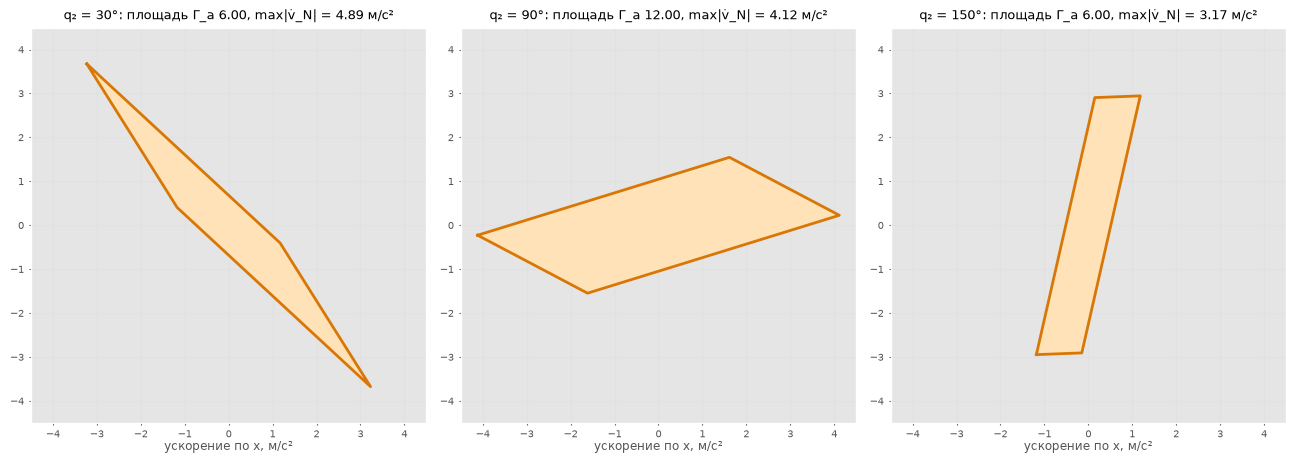

Оценка чисто кинематическая: реальные пределы ускорений задают моменты приводов и инерция звеньев и груза.


In [16]:
l = (1.0, 1.0); b = np.array([1.0, 3.0])                     # пределы ускорений b_i, рад/с²
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, q2 in zip(axs, np.radians([30, 90, 150])):
    J = jac2r((0.3, q2), l); D = polygon_image(J, b)
    ax.fill(D[:, 0], D[:, 1], color='#FFE2B8'); ax.plot(np.r_[D[:, 0], D[0, 0]], np.r_[D[:, 1], D[0, 1]], color=AMB, lw=2)
    ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5)
    ax.set_xlabel('ускорение по x, м/с²'); ax.set_title('q₂ = %.0f°: площадь Γ_a %.2f, max|v̇_N| = %.2f м/с²' % (np.degrees(q2), abs(np.linalg.det(J)) * 4 * b[0] * b[1], np.linalg.norm(D, axis=1).max()), fontsize=9)
plt.tight_layout(); plt.show()
print('Оценка чисто кинематическая: реальные пределы ускорений задают моменты приводов и инерция звеньев и груза.')

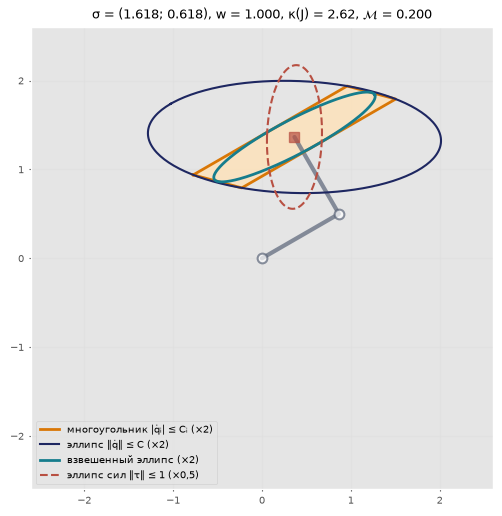

interactive(children=(FloatSlider(value=30.0, description='q₁, °', max=180.0, min=-180.0, step=5.0), FloatSlid…

In [17]:
def show_2r(q1=30., q2=90., C1=0.1, C2=0.5):
    l = (1.0, 1.0); q = np.radians([q1, q2]); Cv = np.array([C1, C2]); J = jac2r(q, l)
    U, S, _ = np.linalg.svd(J); t = np.linspace(0, 2 * np.pi, 300); circ = np.vstack([np.cos(t), np.sin(t)])
    fig, ax = plt.subplots(figsize=(6, 6)); pts = draw_arm2d(ax, q, l, color=GREY, lw=3, alpha=.7); p = pts[-1]; k = 2.0
    poly = polygon_image(J, Cv); ax.fill(p[0] + k * poly[:, 0], p[1] + k * poly[:, 1], color='#FFE2B8', alpha=.8)
    ax.plot(p[0] + k * np.r_[poly[:, 0], poly[0, 0]], p[1] + k * np.r_[poly[:, 1], poly[0, 1]], color=AMB, lw=2, label='многоугольник |q̇ᵢ| ≤ Cᵢ (×2)')
    e = ellipse_image(J, np.linalg.norm(Cv)); ax.plot(p[0] + k * e[:, 0], p[1] + k * e[:, 1], color=NAVY, lw=1.5, label='эллипс ‖q̇‖ ≤ C (×2)')
    Uw, Sw, _ = np.linalg.svd(J @ np.diag(Cv)); ew = (Uw * Sw) @ circ; ax.plot(p[0] + k * ew[0], p[1] + k * ew[1], color=TEAL, lw=2, label='взвешенный эллипс (×2)')
    if S[-1] > 1e-3:
        fe = (U / S) @ circ * 0.5; ax.plot(p[0] + fe[0], p[1] + fe[1], color=RED, lw=1.5, ls='--', label='эллипс сил ‖τ‖ ≤ 1 (×0,5)')
    ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.6, 2.6); ax.legend(fontsize=7, loc='lower left')
    ax.set_title(r'σ = (%.3f; %.3f), w = %.3f, κ(J) = %s, $\mathcal{M}$ = %.3f' % (S[0], S[1], S[0] * S[1], ('%.2f' % (S[0] / S[1])) if S[1] > 1e-9 else '∞', abs(np.linalg.det(J)) * 4 * C1 * C2), fontsize=9)
    plt.show()
show_2r()                                                     # статичный кадр для выполненного ноутбука
try:
    from ipywidgets import interact, FloatSlider
    interact(show_2r, q1=FloatSlider(min=-180, max=180, step=5, value=30, description='q₁, °'),
             q2=FloatSlider(min=-180, max=180, step=5, value=90, description='q₂, °'),
             C1=FloatSlider(min=0.05, max=1.0, step=0.05, value=0.1, description='C₁, рад/с'),
             C2=FloatSlider(min=0.05, max=1.0, step=0.05, value=0.5, description='C₂, рад/с'))
except ImportError:
    print('для ползунков установите ipywidgets: pip install ipywidgets')

## Демонстрация 14. Ведём инструмент UR5e по прямой: покачивание в декартовых осях (§ 3.12)

Так работает режим «двигать инструмент вдоль оси $x$ базы» на пульте: командная скорость $\boldsymbol{\mathcal V}^\ast=(\mathbf 0;\ 0{,}1\ \text{м/с вдоль }x_0)$ постоянна, контроллер на каждом такте $\Delta t$ строит $J(\mathbf q)$ и вычисляет $\dot{\mathbf q}$.

* (а) **Разомкнутая схема** $\dot{\mathbf q}=J^{-1}\boldsymbol{\mathcal V}^\ast$, $\mathbf q\leftarrow\mathbf q+\dot{\mathbf q}\Delta t$: ошибка явного метода Эйлера накапливается, схват уходит с прямой (пропорционально шагу).
* (б) **Замкнутая схема** $\dot{\mathbf q}=J^{-1}(\boldsymbol{\mathcal V}^\ast+K\mathbf e)$ с ошибкой позы $\mathbf e=(\delta\boldsymbol\varphi;\Delta\mathbf p)$, $\delta\boldsymbol\varphi=\log(R^\ast R^{\mathrm T})^{\vee}$ — мост к лекции 4: ошибка остаётся малой и не растёт.
* (в) **Насыщение приводов** $\lvert\dot q_i\rvert\le\pi$ рад/с (паспорт UR5e) у кистевой особенности. Сначала числа конспекта при $q_5=0{,}5^\circ$, затем проход шва со скоростью 0,25 м/с мимо $q_5\approx1{,}4^\circ$: равномерное масштабирование вектора $\dot{\mathbf q}$ оставляет инструмент на прямой и сохраняет ориентацию, но замедляет его; покомпонентное обрезание уводит инструмент с прямой и поворачивает его.
* (г) **Предупреждение о численном артефакте.** Команда вдоль $-x_0$ выводит схват на границу зоны (локтевая особенность, $q_3\to0$). Явный Эйлер с $J^{-1}$ без обратной связи и без насыщения «перепрыгивает» особую точку: пиковые скорости зависят от шага, локоть переходит на другую ветвь, схват уходит с прямой на десятки сантиметров. Это свойство численной схемы, а не робота; честная модель (замкнутый контур и насыщение) просто останавливает схват у границы.

**Сломай и посмотри** (`BREAK = True`): в части (б) коэффициент $K=0$ — замкнутая схема превращается в разомкнутую.

(а) разомкнутая схема, 5 с: отклонение от заданной точки 0.571 мм при Δt = 10 мс и 0.286 мм при Δt = 5 мс (∝ Δt)
(б) замкнутая схема, K = 5 с⁻¹, Δt = 10 мс: наибольшее отклонение 0.031 мм, в конце 0.031 мм
(в) q5 = 0,5°: J⁻¹V требует max|q̇| = 4.85 рад/с > π
    масштабирование: V = [ 0.     -0.     -0.      0.0648  0.      0.    ] ;  обрезание: V = [-0.2598  0.8227  0.0053 -0.0121 -0.0347  0.1229]
Сверка с конспектом:
  совпадает   масштабирование: скорость вдоль x0: расчёт 0.0648, конспект 0,065 м/с
  совпадает   обрезание: модуль линейной скорости: расчёт 0.1283, конспект 0,128 м/с
  совпадает   обрезание: угол к заданному направлению: расчёт 95.4, конспект 95 °
  совпадает   обрезание: паразитная угловая скорость: расчёт 0.863, конспект 0,86 рад/с


    без насыщения (нереализуемо)   max|q̇| = 4.93 рад/с, уход с прямой до 0.1 мм, ошибка ориентации до 0.00°, мин. скорость вдоль шва 0.250 м/с
    обрезание |q̇ᵢ| ≤ π            max|q̇| = 3.14 рад/с, уход с прямой до 49.1 мм, ошибка ориентации до 13.15°, мин. скорость вдоль шва 0.198 м/с
    масштабирование вектора q̇     max|q̇| = 3.14 рад/с, уход с прямой до 0.1 мм, ошибка ориентации до 0.00°, мин. скорость вдоль шва 0.160 м/с


(г) разомкнутая J⁻¹, Δt = 5 мс: пик max|q̇| = 175 рад/с, q3: 80.2° -> -6.2°, отклонение схвата 0.14 м
(г) разомкнутая J⁻¹, Δt = 1 мс: пик max|q̇| = 1267 рад/с, q3: 80.2° -> 63.8°, отклонение схвата 0.26 м


    честная модель (K = 5, масштабирование): пик 3.14 рад/с, q3 в конце 0.03°, схват отстал от команды на 0.16 м и стоит у границы


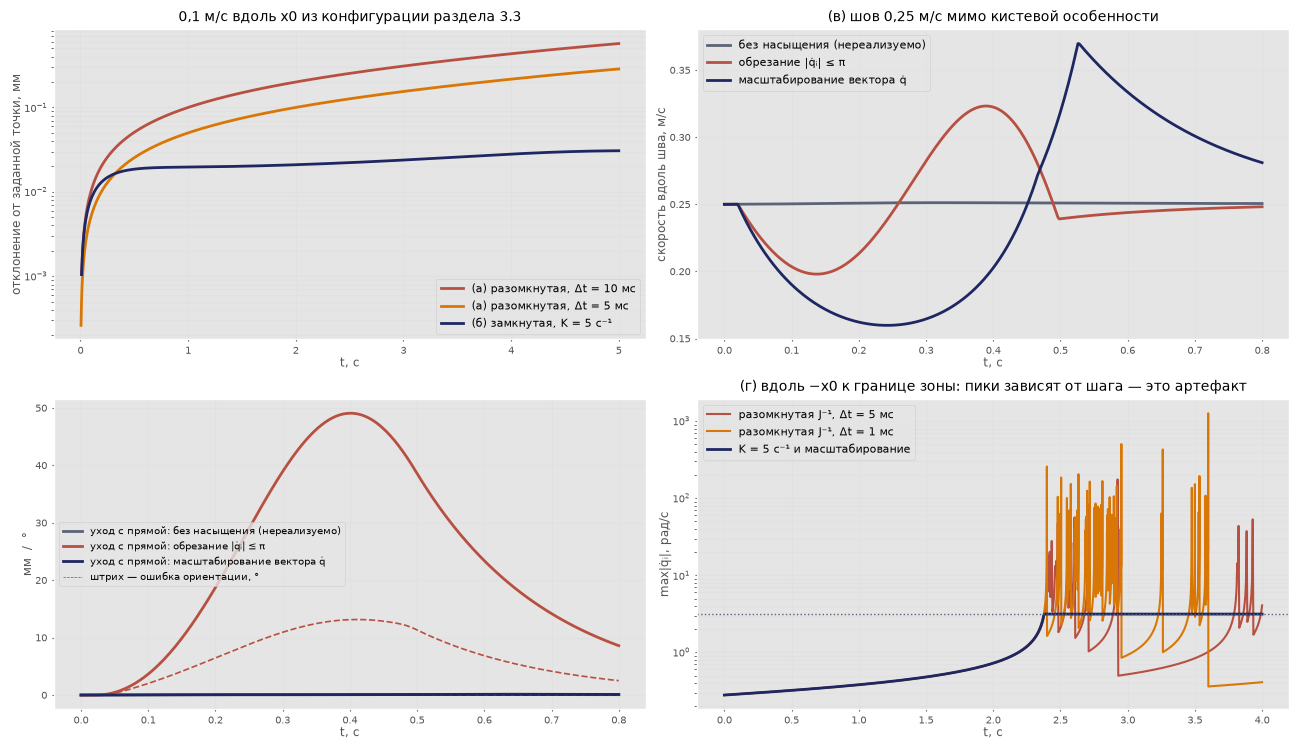

In [18]:
BREAK = False
ur = make_ur5e(); QD_MAX = ur.qd_max                                   # паспорт: 180°/с = π рад/с
def jog(q0, V, Tend, dt, Kp=0.0, sat=None, mu=None):
    """Покачивание: V — командная скорость (ω; v); Kp — обратная связь по позе; sat — None, 'clip', 'scale'."""
    q = np.array(q0, float); T = ur.forward(q.copy()); p0, R0 = T.t_3_1.ravel().copy(), T.r_3_3.copy()
    n = V[3:] / np.linalg.norm(V[3:]); out = {k: [] for k in ('t', 'perp', 'lag', 'rot', 'qdmax', 'speed', 'om', 'q3', 'q')}
    for k in range(int(round(Tend / dt)) + 1):
        t = k * dt; T = ur.forward(q.copy()); J = ur.jacobian_book(); p = T.t_3_1.ravel()
        e = np.r_[so3_log(R0 @ T.r_3_3.T), p0 + V[3:] * t - p]          # e = (δφ; Δp)
        cmd = V + Kp * e
        qd = np.linalg.solve(J, cmd) if mu is None else J.T @ np.linalg.solve(J @ J.T + mu ** 2 * np.eye(6), cmd)
        if sat == 'clip':
            qd = np.clip(qd, -QD_MAX, QD_MAX)
        elif sat == 'scale':
            m = np.max(np.abs(qd) / QD_MAX); qd = qd / m if m > 1 else qd
        Vt = J @ qd; dpv = p - p0
        out['t'].append(t); out['perp'].append(np.linalg.norm(dpv - (dpv @ n) * n)); out['lag'].append(np.linalg.norm(V[3:]) * t - dpv @ n)
        out['rot'].append(np.linalg.norm(e[:3])); out['qdmax'].append(np.abs(qd).max()); out['speed'].append(Vt[3:] @ n)
        out['om'].append(np.linalg.norm(Vt[:3])); out['q3'].append(q[2]); out['q'].append(q.copy())
        q = q + dt * qd
    return {k: np.array(v) for k, v in out.items()}

V = np.array([0, 0, 0, 0.1, 0, 0])
A1 = jog(Q33, V, 5.0, 0.01); A2 = jog(Q33, V, 5.0, 0.005)
B = jog(Q33, V, 5.0, 0.01, Kp=0.0 if BREAK else 5.0)
dev = lambda r: np.hypot(r['perp'], r['lag'])
print('(а) разомкнутая схема, 5 с: отклонение от заданной точки %.3f мм при Δt = 10 мс и %.3f мм при Δt = 5 мс (∝ Δt)' % (1e3 * dev(A1)[-1], 1e3 * dev(A2)[-1]))
print('(б) замкнутая схема, K = %g с⁻¹, Δt = 10 мс: наибольшее отклонение %.3f мм, в конце %.3f мм%s' % (0 if BREAK else 5, 1e3 * dev(B).max(), 1e3 * dev(B)[-1], '  (СЛОМАНО: K = 0)' if BREAK else ''))

# (в) насыщение: числа конспекта при q5 = 0,5°
qs = Q33.copy(); qs[4] = np.radians(0.5); ur.forward(qs.copy()); J = ur.jacobian_book()
qd = np.linalg.solve(J, V); kmax = np.min(QD_MAX / np.abs(qd))
Vs, Vc = J @ (kmax * qd), J @ np.clip(qd, -QD_MAX, QD_MAX)
ang = np.degrees(np.arccos(Vc[3] / np.linalg.norm(Vc[3:])))
print('(в) q5 = 0,5°: J⁻¹V требует max|q̇| = %.2f рад/с > π' % np.abs(qd).max())
print('    масштабирование: V =', Vs.round(4), ';  обрезание: V =', Vc.round(4))
print('Сверка с конспектом:')
check('масштабирование: скорость вдоль x0', Vs[3], '0,065', 'м/с'); check('обрезание: модуль линейной скорости', np.linalg.norm(Vc[3:]), '0,128', 'м/с')
check('обрезание: угол к заданному направлению', ang, '95', '°'); check('обрезание: паразитная угловая скорость', np.linalg.norm(Vc[:3]), '0,86', 'рад/с')

qw = Q33.copy(); qw[4] = np.radians(2.0); Vw = np.array([0, 0, 0, -0.25, 0, 0])
runs = {'без насыщения (нереализуемо)': jog(qw, Vw, 0.8, 0.002, Kp=5.0), 'обрезание |q̇ᵢ| ≤ π': jog(qw, Vw, 0.8, 0.002, Kp=5.0, sat='clip'),
        'масштабирование вектора q̇': jog(qw, Vw, 0.8, 0.002, Kp=5.0, sat='scale')}
for name, r in runs.items():
    print('    %-30s max|q̇| = %.2f рад/с, уход с прямой до %.1f мм, ошибка ориентации до %.2f°, мин. скорость вдоль шва %.3f м/с' % (
        name, r['qdmax'].max(), 1e3 * r['perp'].max(), np.degrees(r['rot'].max()), r['speed'].min()))

# (г) численный артефакт явного Эйлера у локтевой особенности
Vb = np.array([0, 0, 0, -0.1, 0, 0])
G = {dt: jog(Q33, Vb, 4.0, dt) for dt in (0.005, 0.001)}
for dt, r in G.items():
    print('(г) разомкнутая J⁻¹, Δt = %g мс: пик max|q̇| = %.0f рад/с, q3: %.1f° -> %.1f°, отклонение схвата %.2f м' % (
        dt * 1e3, r['qdmax'].max(), np.degrees(r['q3'][0]), np.degrees(r['q3'][-1]), dev(r)[-1]))
Gh = jog(Q33, Vb, 4.0, 0.005, Kp=5.0, sat='scale')
print('    честная модель (K = 5, масштабирование): пик %.2f рад/с, q3 в конце %.2f°, схват отстал от команды на %.2f м и стоит у границы' % (
    Gh['qdmax'].max(), np.degrees(Gh['q3'][-1]), dev(Gh)[-1]))

fig, axs = plt.subplots(2, 2, figsize=(13, 7.5))
ax = axs[0, 0]
ax.semilogy(A1['t'][1:], 1e3 * dev(A1)[1:], color=RED, lw=2, label='(а) разомкнутая, Δt = 10 мс')   # при t = 0 отклонение равно нулю
ax.semilogy(A2['t'][1:], 1e3 * dev(A2)[1:], color=AMB, lw=2, label='(а) разомкнутая, Δt = 5 мс')
ax.semilogy(B['t'][1:], 1e3 * dev(B)[1:], color=NAVY, lw=2, label='(б) замкнутая, K = 5 с⁻¹')
ax.set_xlabel('t, с'); ax.set_ylabel('отклонение от заданной точки, мм'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8)
ax.set_title('0,1 м/с вдоль x0 из конфигурации раздела 3.3', fontsize=10)
cols = {'без насыщения (нереализуемо)': GREY, 'обрезание |q̇ᵢ| ≤ π': RED, 'масштабирование вектора q̇': NAVY}
ax = axs[0, 1]
for name, r in runs.items():
    ax.plot(r['t'], r['speed'], color=cols[name], lw=2, label=name)      # проекция скорости инструмента на направление шва (−x0)
ax.set_xlabel('t, с'); ax.set_ylabel('скорость вдоль шва, м/с'); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title('(в) шов 0,25 м/с мимо кистевой особенности', fontsize=10)
ax = axs[1, 0]
for name, r in runs.items():
    ax.plot(r['t'], 1e3 * r['perp'], color=cols[name], lw=2, label='уход с прямой: ' + name)
    ax.plot(r['t'], np.degrees(r['rot']), color=cols[name], lw=1.2, ls='--')
ax.plot([], [], color=GREY, ls='--', label='штрих — ошибка ориентации, °')
ax.set_xlabel('t, с'); ax.set_ylabel('мм  /  °'); ax.grid(alpha=.3); ax.legend(fontsize=7)
ax = axs[1, 1]
for (dt, r), col in zip(G.items(), (RED, AMB)):
    ax.semilogy(r['t'], r['qdmax'], color=col, lw=1.5, label='разомкнутая J⁻¹, Δt = %g мс' % (dt * 1e3))
ax.semilogy(Gh['t'], Gh['qdmax'], color=NAVY, lw=2, label='K = 5 с⁻¹ и масштабирование')
ax.axhline(np.pi, color=GREY, ls=':', lw=1); ax.set_xlabel('t, с'); ax.set_ylabel('max|q̇ᵢ|, рад/с'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8)
ax.set_title('(г) вдоль −x0 к границе зоны: пики зависят от шага — это артефакт', fontsize=10)
plt.tight_layout(); plt.show()

## Итог сверки с конспектом

Ячейка ниже подсчитывает все проверки `check` в ноутбуке. Строки «РАСХОДИТСЯ» означают, что число в Лекции_03.md и расчёт нужно согласовать.

In [19]:
bad = [n for n, ok in CHECKS if not ok]
print('проверок: %d, совпало: %d, расходится: %d' % (len(CHECKS), len(CHECKS) - len(bad), len(bad)))
for n in bad:
    print('  РАСХОДИТСЯ:', n)

проверок: 120, совпало: 120, расходится: 0
